# Bayesian Marketing Mix Model — Take-Home Analysis

**Date:** July 2026  
**Tools:** PyMC (latest), ArviZ, NumPy, pandas, Matplotlib

**Overview:** This notebook develops a Bayesian Marketing Mix Model (MMM) using two years of weekly revenue and marketing spend data from seven channels. It estimates channel contributions to revenue and return on investment (ROI) using geometric adstock with learnable decay rates, Fourier seasonality, and a linear trend. Estimates are reported with posterior uncertainty.


# 1. Import the tools

This analysis uses PyMC for probabilistic modeling, ArviZ for Bayesian diagnostics, and the PyData libraries for data handling and visualization. A shared `RANDOM_SEED` is set here and reused throughout the notebook to support reproducible results.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pymc as pm
import pytensor
import pytensor.tensor as pt
import arviz as az
import xarray as xr
from sklearn.preprocessing import MaxAbsScaler

# --- Reproducibility ---
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# --- Plotting configuration ---
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('ggplot')
az.style.use("arviz-darkgrid")
plt.rcParams.update({
    'figure.figsize': (14, 5),
    'figure.dpi': 120,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'font.size': 11,
})

print(f"PyMC version : {pm.__version__}")
print(f"ArviZ version: {az.__version__}")


PyMC version : 6.2.0
ArviZ version: 1.2.0


# 2. Load the data

The `start_of_week` values use the `DD-MM-YY` format. Parsing them with the explicit format `%d-%m-%y` prevents Pandas from interpreting the dates as month-first. The data is then sorted chronologically and checked for basic quality issues.


In [2]:
df = pd.read_csv('data/MMM_test_data.csv')
df['start_of_week'] = pd.to_datetime(df['start_of_week'], format='%d-%m-%y')
df = df.sort_values('start_of_week').reset_index(drop=True)

spend_cols = [c for c in df.columns if c.startswith('spend')]

print("--- Shape ---")
print(f"{df.shape[0]} weeks x {df.shape[1]} columns")
print(f"Date range: {df['start_of_week'].min().date()} to {df['start_of_week'].max().date()}")

print("\n--- Missing Values ---")
print(df.isnull().sum().to_string())

print(f"\n--- Duplicate Rows: {df.duplicated().sum()} ---")

print("\n--- Data Types ---")
print(df.dtypes.to_string())

display(df.head())
display(df.describe())


--- Shape ---
104 weeks x 9 columns
Date range: 2020-08-30 to 2022-08-21

--- Missing Values ---
start_of_week      0
revenue            0
spend_channel_1    0
spend_channel_2    0
spend_channel_3    0
spend_channel_4    0
spend_channel_5    0
spend_channel_6    0
spend_channel_7    0

--- Duplicate Rows: 0 ---

--- Data Types ---
start_of_week      datetime64[ns]
revenue                   float64
spend_channel_1           float64
spend_channel_2           float64
spend_channel_3           float64
spend_channel_4           float64
spend_channel_5           float64
spend_channel_6           float64
spend_channel_7           float64


,start_of_week,revenue,spend_channel_1,spend_channel_2,spend_channel_3,spend_channel_4,spend_channel_5,spend_channel_6,spend_channel_7
0,2020-08-30,157906.75,2625.48,262.71,12954.12,3609.63,12955.29,12659.12,19379.79
1,2020-09-06,186425.68,2634.01,108.66,8760.28,4560.60,12747.70,12338.18,22473.45
2,2020-09-13,161607.39,2087.08,110.32,7155.42,4362.96,15015.41,10811.15,22596.05
3,2020-09-20,180089.13,1690.70,52.79,15185.22,3883.41,15521.41,12890.22,24728.73
4,2020-09-27,217793.98,1547.30,80.56,18524.05,4043.09,15793.74,12642.55,26515.48


,start_of_week,revenue,spend_channel_1,spend_channel_2,spend_channel_3,spend_channel_4,spend_channel_5,spend_channel_6,spend_channel_7
count,104,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000
mean,2021-08-25 12:00:00,136490.190673,1245.604808,343.640962,19507.177981,6915.136731,8575.611442,5063.699038,27701.367404
min,2020-08-30 00:00:00,63207.090000,0.000000,4.370000,5938.130000,3602.200000,747.460000,0.000000,9391.210000
25%,2021-02-26 06:00:00,101675.685000,334.275000,120.470000,13879.000000,5113.937500,2902.032500,0.000000,19797.710000
50%,2021-08-25 12:00:00,128790.460000,856.870000,202.020000,17929.450000,6194.400000,6879.270000,2423.095000,24248.640000
75%,2022-02-21 18:00:00,157707.280000,1658.032500,553.075000,22252.262500,7470.557500,14367.582500,8701.960000,33852.652500
max,2022-08-21 00:00:00,418186.380000,8513.830000,1605.850000,49689.380000,22629.690000,33009.650000,33692.830000,77488.420000
std,NaN,50810.253012,1388.384632,332.988218,8714.759886,3123.172035,6956.787524,6689.472660,12176.293684


The dataset contains **104 weekly observations**, covering two years from August 2020 to August 2022. The initial checks show no missing values or duplicate rows. Numeric columns are stored as `float64`, and `start_of_week` has been converted to `datetime64`.


# 3. Explore the data

Before building the model, examine the patterns in revenue and marketing spend. This section reviews revenue over time, channel spend, correlations, distributions, rolling averages, trend, seasonality, and each channel's share of total spend.


C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\2724224418.py:13: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


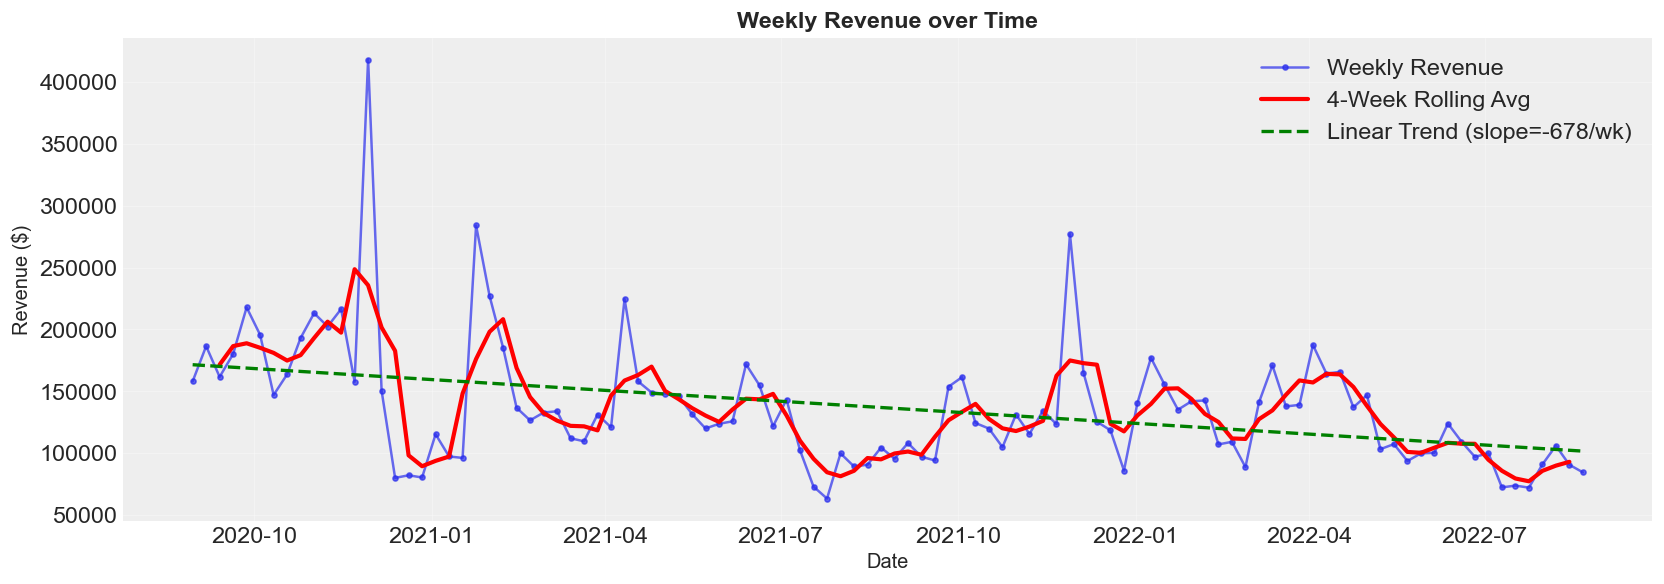

In [3]:
# 3a. Revenue over time with rolling average and linear trend
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df['start_of_week'], df['revenue'], marker='o', markersize=3, linewidth=1.5, label='Weekly Revenue', alpha=0.7)
ax.plot(df['start_of_week'], df['revenue'].rolling(4, center=True).mean(), color='red', linewidth=2.5, label='4-Week Rolling Avg')

# Linear trend line
z = np.polyfit(np.arange(len(df)), df['revenue'], 1)
ax.plot(df['start_of_week'], np.polyval(z, np.arange(len(df))), '--', color='green', linewidth=2, label=f'Linear Trend (slope={z[0]:+.0f}/wk)')

ax.set_title('Weekly Revenue over Time', fontweight='bold')
ax.set_xlabel('Date'); ax.set_ylabel('Revenue ($)')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


**Revenue over time:** Weekly revenue ranges from about $60,000 to $420,000, with visible peaks near the end of the fourth quarter in both years. The four-week rolling average smooths weekly variation and makes the recurring pattern easier to see. The linear trend indicates a modest upward movement over the two-year period, supporting the use of a linear trend term in the model.


C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\3805882018.py:17: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


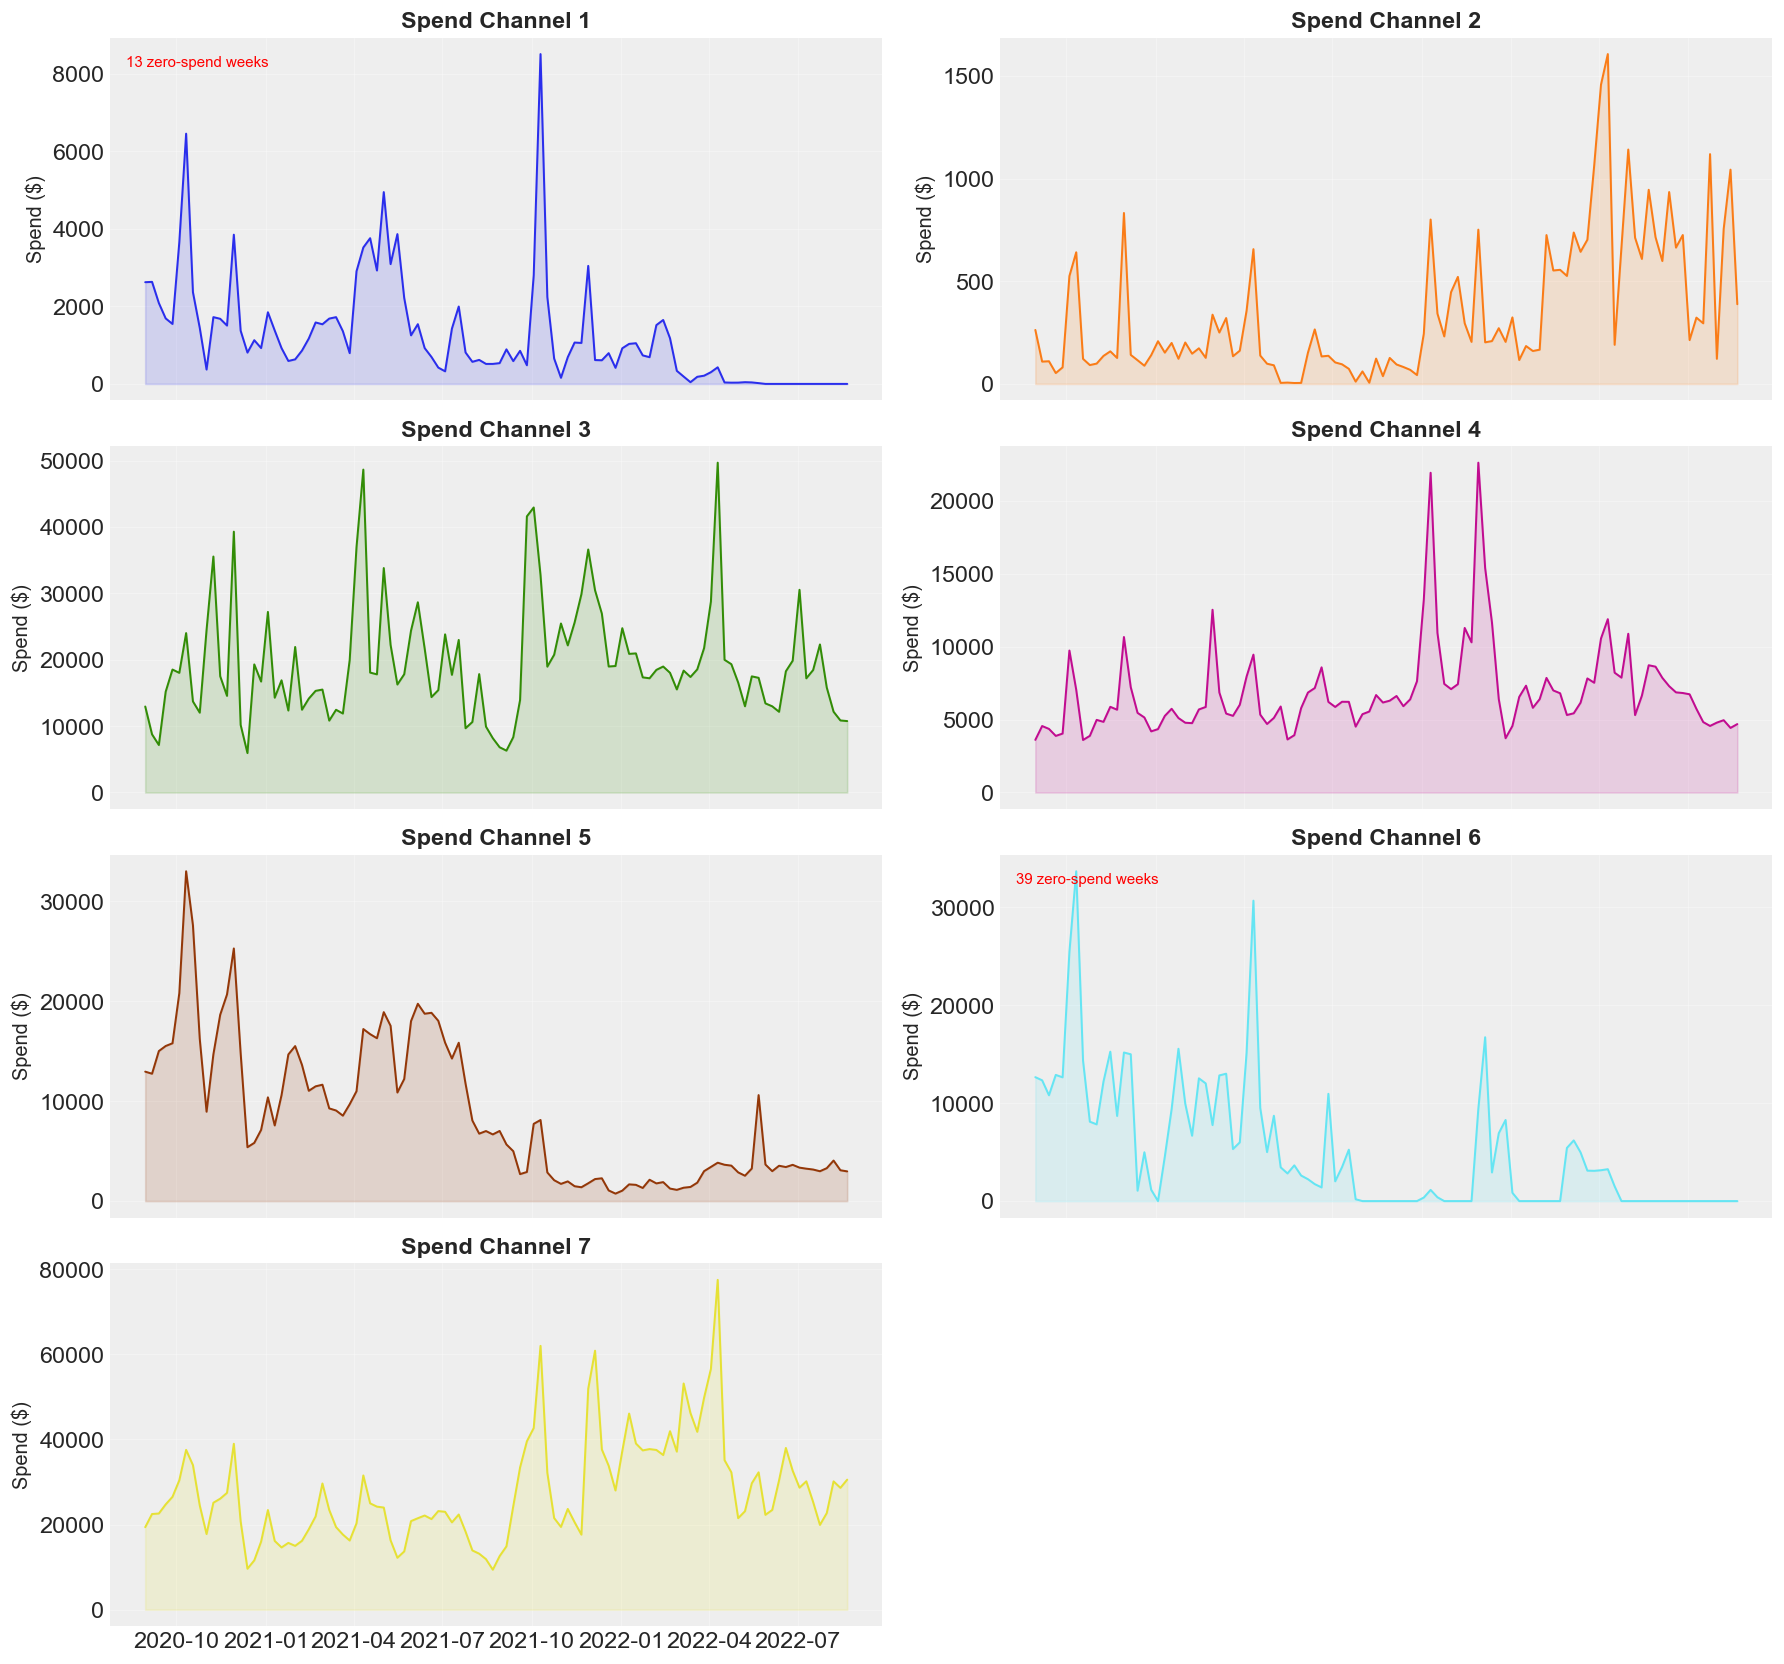

In [4]:
# 3b. Spend of each channel over time
fig, axes = plt.subplots(4, 2, figsize=(15, 14), sharex=True)
axes = axes.flatten()

for i, col in enumerate(spend_cols):
    axes[i].plot(df['start_of_week'], df[col], color=f'C{i}', linewidth=1.2)
    axes[i].fill_between(df['start_of_week'], df[col], alpha=0.15, color=f'C{i}')
    axes[i].set_title(col.replace('_', ' ').title(), fontweight='bold')
    axes[i].set_ylabel('Spend ($)')
    axes[i].grid(True, alpha=0.3)
    # Annotate zero-spend weeks
    n_zero = (df[col] == 0).sum()
    if n_zero > 0:
        axes[i].annotate(f'{n_zero} zero-spend weeks', xy=(0.02, 0.92), xycoords='axes fraction', fontsize=9, color='red')

axes[-1].axis('off')
plt.tight_layout(); plt.show()


**Channel spend over time:** Spend patterns differ across channels. Channel 7 has the largest, most frequent bursts; Channel 2 operates at a much smaller scale; and Channel 6 has many zero-spend weeks, suggesting intermittent use. Because the model does not include saturation curves, spend enters the model through a linear response. The zero-spend weeks remain valid observations in that setup.


C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\3615524222.py:14: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


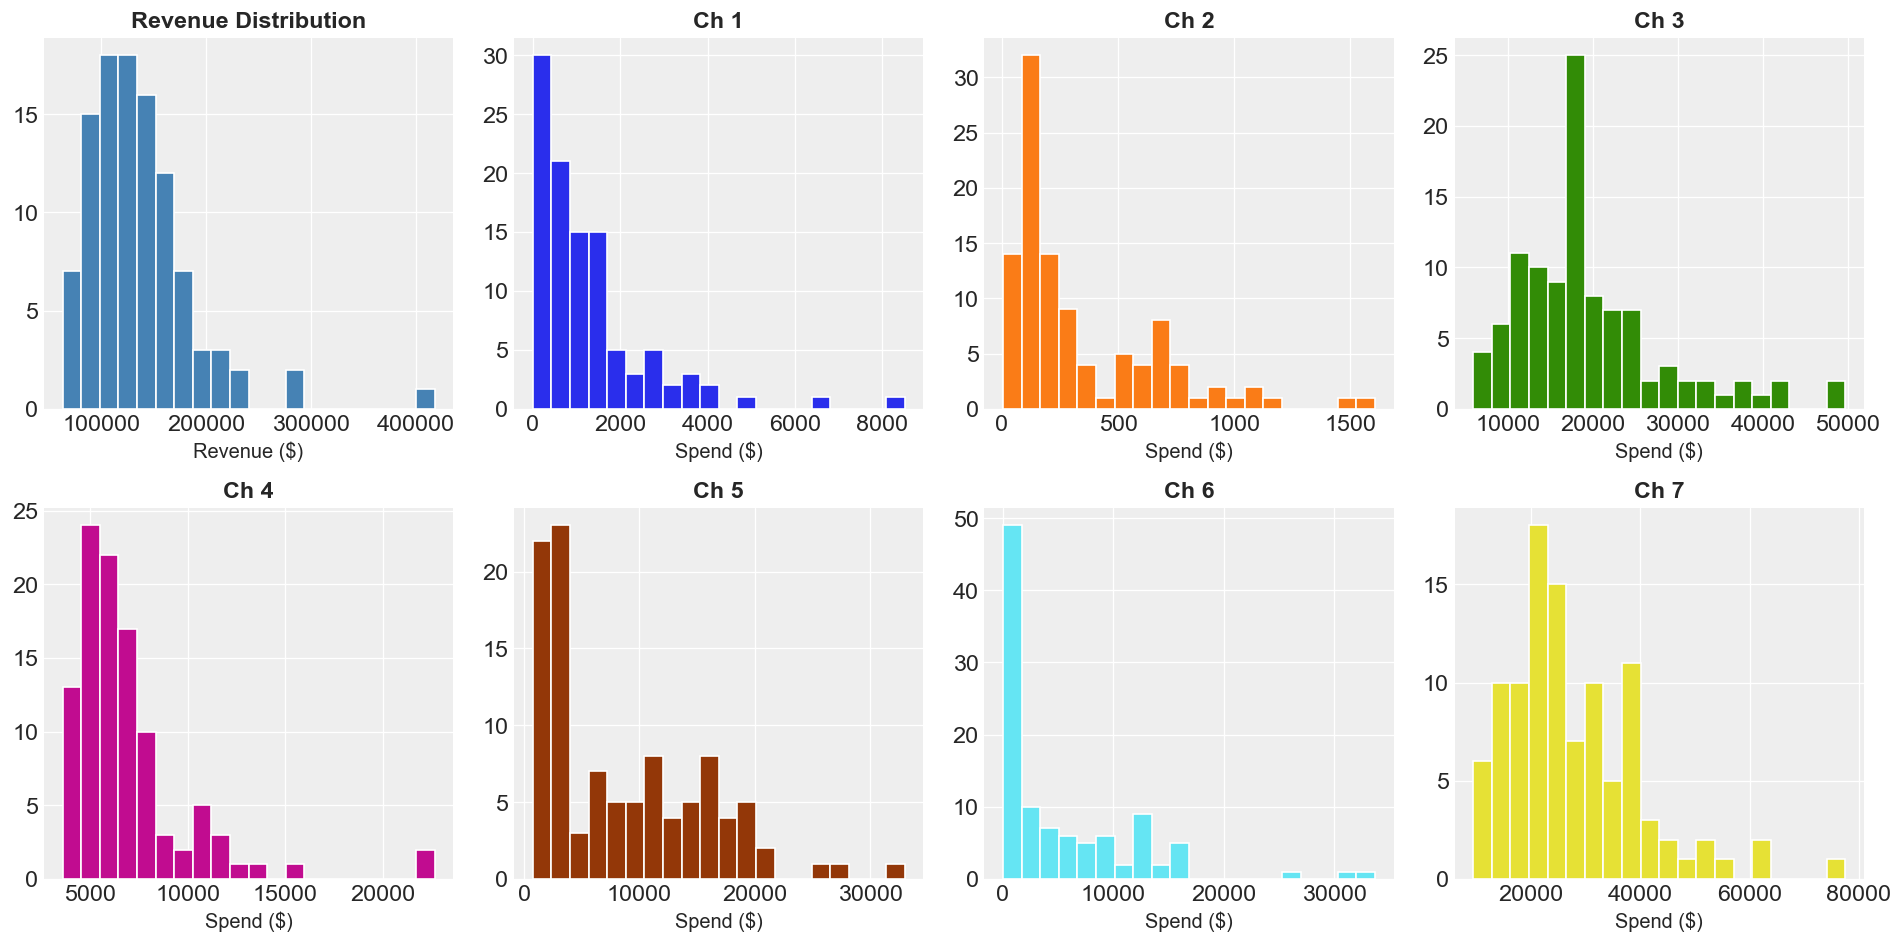

In [5]:
# 3c. Distribution of revenue and spends
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

axes[0].hist(df['revenue'], bins=20, color='steelblue', edgecolor='white')
axes[0].set_title('Revenue Distribution', fontweight='bold')
axes[0].set_xlabel('Revenue ($)')

for i, col in enumerate(spend_cols):
    axes[i+1].hist(df[col], bins=20, color=f'C{i}', edgecolor='white')
    axes[i+1].set_title(col.replace('spend_channel_', 'Ch ').title(), fontweight='bold')
    axes[i+1].set_xlabel('Spend ($)')

plt.tight_layout(); plt.show()


**Distribution patterns:** Revenue is right-skewed, with a long upper tail associated with peak periods. Most spend channels are also right-skewed, which is common when media is purchased in bursts. Channel 6 has a large number of zero-spend observations. These patterns help guide prior selection; in particular, typical revenue is expected to be below the maximum observed value.


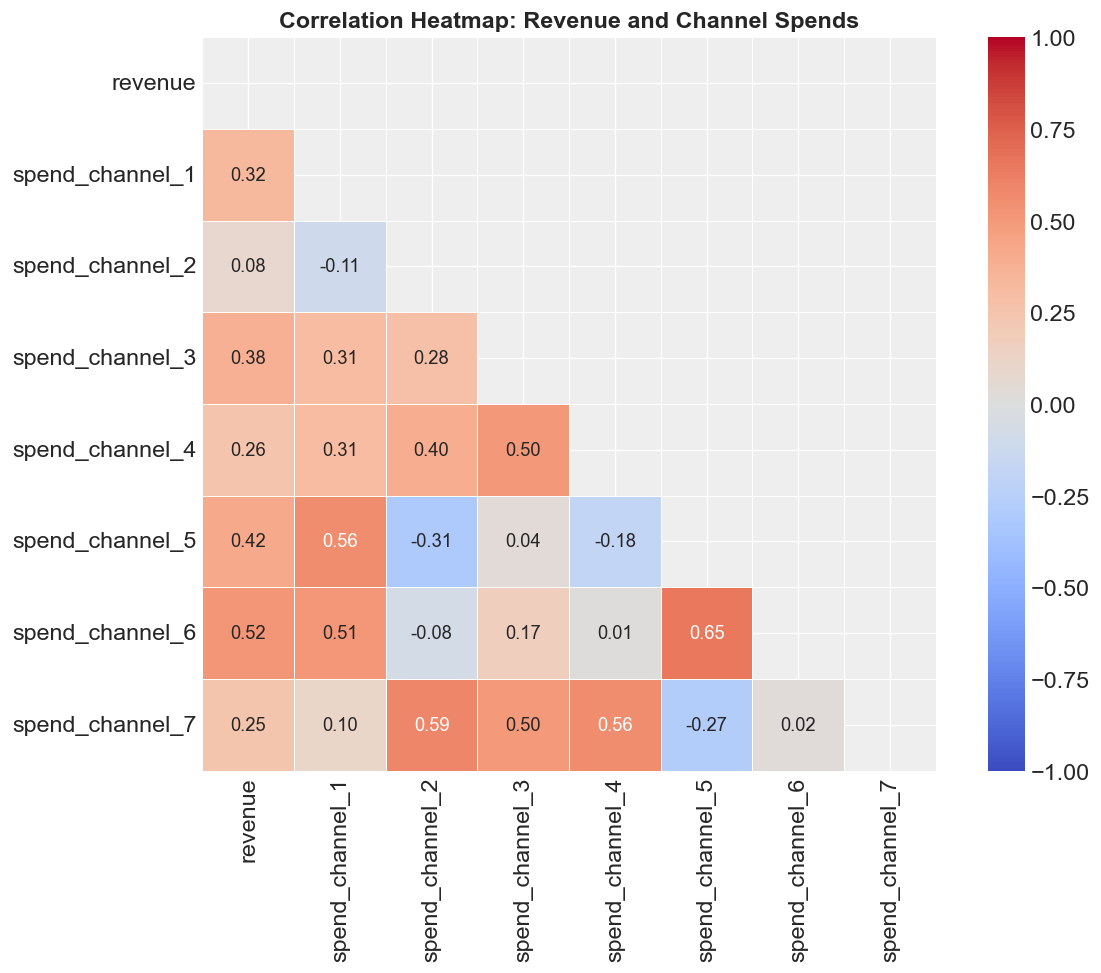

In [6]:
# 3d. Correlation heatmap
plt.figure(figsize=(10, 8))
corr = df[['revenue'] + spend_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Correlation Heatmap: Revenue and Channel Spends', fontweight='bold')
plt.show()


**Correlation patterns:** Channels 3, 5, and 7 have the strongest positive correlations with revenue. Several channels are also correlated with one another; for example, the correlation between Channels 3 and 7 is about 0.61. This overlap creates multicollinearity. In the Bayesian model, it can lead to wider joint posterior intervals, reflecting the difficulty of separating the channels' individual effects.


C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\2357587695.py:6: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


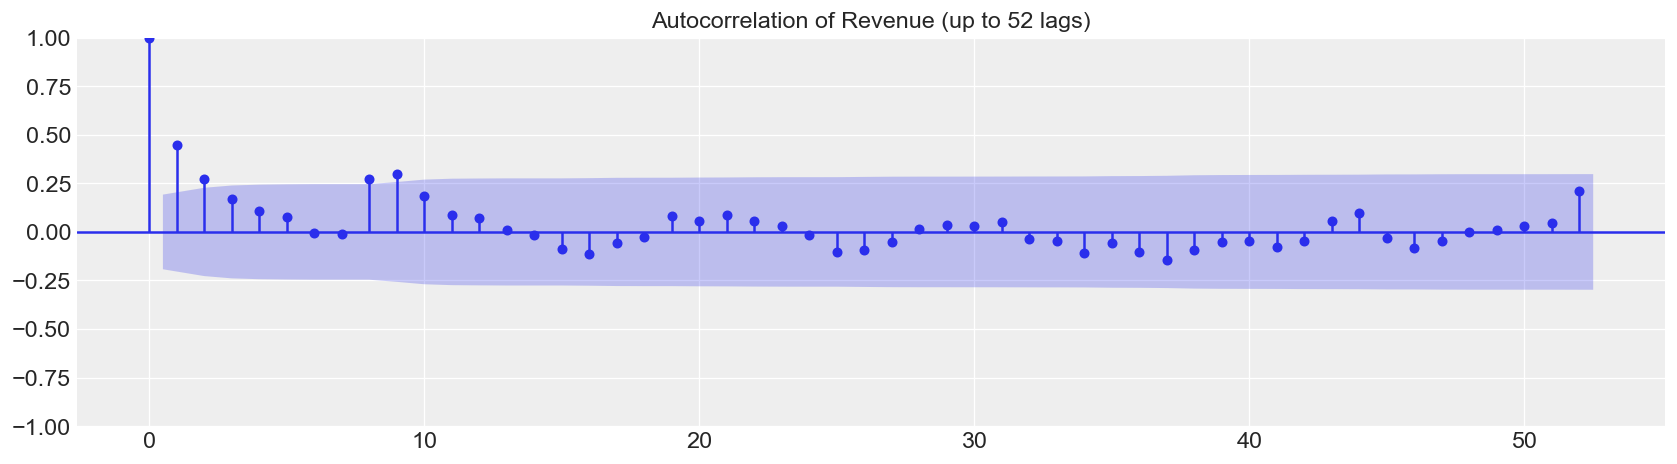

In [7]:
# 3e. Seasonality inspection via autocorrelation
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(df['revenue'], lags=52, ax=ax, title='Autocorrelation of Revenue (up to 52 lags)')
plt.tight_layout(); plt.show()


**Seasonality check:** The autocorrelation plot dips around lag 26 and rises again near lag 52, a pattern consistent with annual seasonality in weekly data. This supports using Fourier terms with a period of approximately 52.14 weeks.


C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\150598056.py:8: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


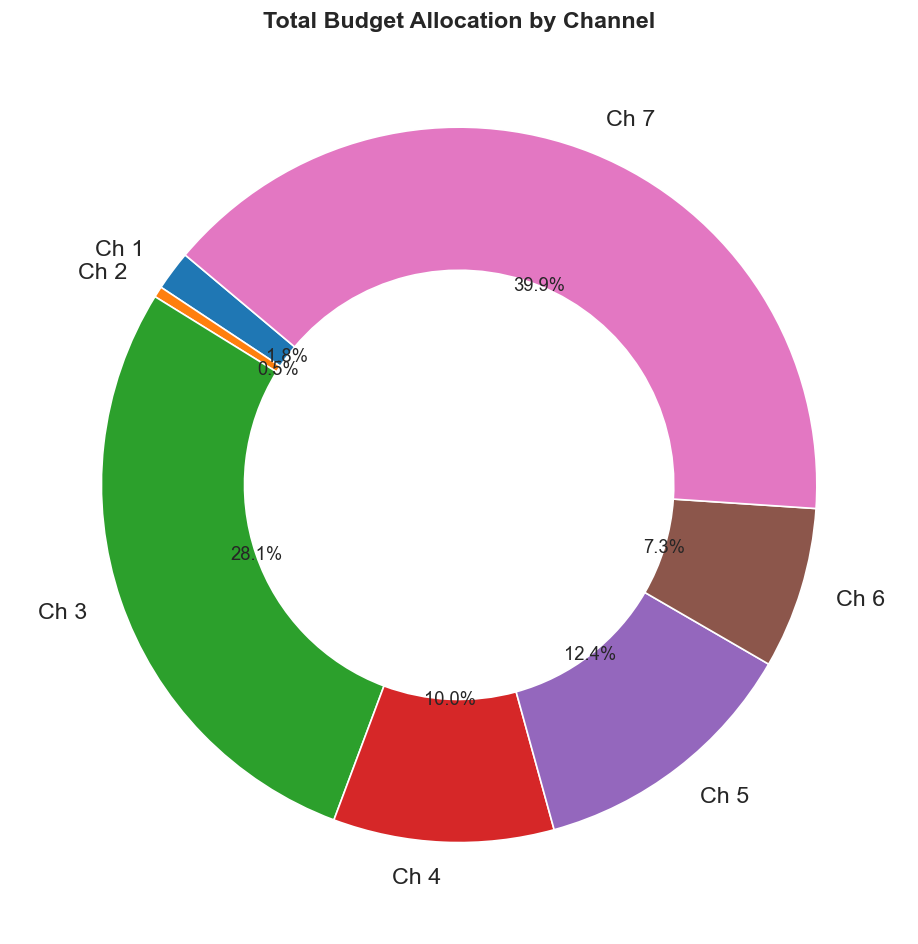

In [8]:
# 3f. Total spend share by channel
total_spend = df[spend_cols].sum()
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(total_spend, labels=[c.replace('spend_channel_', 'Ch ') for c in spend_cols],
       autopct='%1.1f%%', startangle=140, colors=plt.cm.tab10.colors,
       wedgeprops=dict(width=0.4, edgecolor='white'))
ax.set_title('Total Budget Allocation by Channel', fontweight='bold')
plt.tight_layout(); plt.show()


# 4. Prepare the data

Bayesian HMC/NUTS samplers work more effectively when variables use comparable scales. Here, revenue ranges from about $60,000 to $420,000, while channel spend ranges from zero to roughly $77,000.

**Scaling approach:** Apply `MaxAbsScaler` to both the target and predictors. It divides each variable by its maximum absolute value, placing the values on a 0-to-1 scale while preserving exact zero values in spend. Preserving zeros matters for the adstock calculation. On this scale, a channel coefficient of 0.1 represents 10% of peak revenue for one unit of peak spend.

*Data leakage note:* This is a retrospective MMM analysis, not a real-time forecasting exercise. Scaling the full historical dataset consistently is standard for this type of retrospective analysis and does not introduce forecasting leakage.


In [9]:
# Scale target
y_scaler = MaxAbsScaler()
y_scaled = y_scaler.fit_transform(df[['revenue']]).flatten()

# Scale predictors
X_scaler = MaxAbsScaler()
X_scaled = X_scaler.fit_transform(df[spend_cols])

# Build modelling dataframe
df_model = pd.DataFrame(X_scaled, columns=spend_cols)
df_model['revenue'] = y_scaled
df_model['start_of_week'] = df['start_of_week'].values
df_model['t'] = np.arange(len(df)) / (len(df) - 1)  # scaled to [0, 1]

n_obs = len(df_model)
print(f"Observations: {n_obs}")
display(df_model.describe())


Observations: 104


,spend_channel_1,spend_channel_2,spend_channel_3,spend_channel_4,spend_channel_5,spend_channel_6,spend_channel_7,revenue,start_of_week,t
count,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104,104.000000
mean,0.146304,0.213993,0.392582,0.305578,0.259791,0.150290,0.357490,0.326386,2021-08-25 12:00:00,0.500000
min,0.000000,0.002721,0.119505,0.159180,0.022644,0.000000,0.121195,0.151146,2020-08-30 00:00:00,0.000000
25%,0.039263,0.075019,0.279315,0.225984,0.087915,0.000000,0.255492,0.243135,2021-02-26 06:00:00,0.250000
50%,0.100644,0.125803,0.360831,0.273729,0.208402,0.071917,0.312932,0.307974,2021-08-25 12:00:00,0.500000
75%,0.194746,0.344413,0.447827,0.330122,0.435254,0.258273,0.436874,0.377122,2022-02-21 18:00:00,0.750000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2022-08-21 00:00:00,1.000000
std,0.163074,0.207359,0.175385,0.138012,0.210750,0.198543,0.157137,0.121501,NaN,0.292876


# 5. Represent advertising carry-over with adstock

Advertising can continue to affect revenue after the week in which the spend occurs, as consumers retain some memory of the message. Geometric adstock represents this carry-over recursively.

### Formula

$$A_t = S_t + \alpha A_{t-1}, \qquad A_0 = S_0$$

Here, $S_t$ is spend in week $t$, and $\alpha \in [0,1)$ is the decay or retention rate.

### Business meaning

- $\alpha = 0$: No carry-over; only the current week's spend contributes (for example, search ads tied to immediate intent).
- $\alpha = 0.8$: 80% of the previous week's advertising memory is retained (for example, a TV brand campaign).

The transformation is implemented with a **PyTensor scan**, allowing the NUTS sampler to estimate $\alpha$ rather than requiring it to be set in advance.


In [10]:
def geometric_adstock(x: pt.TensorVariable, alpha: pt.TensorVariable) -> pt.TensorVariable:
    """Compute geometric adstock using a PyTensor scan.

    Parameters
    ----------
    x : pt.TensorVariable
        1-D tensor of weekly spend for a single channel (length T).
    alpha : pt.TensorVariable
        Scalar decay rate in [0, 1).

    Returns
    -------
    pt.TensorVariable
        Adstocked spend vector of the same length as x.
    """
    def step(x_t: pt.TensorVariable, a_prev: pt.TensorVariable, alpha: pt.TensorVariable) -> pt.TensorVariable:
        return x_t + alpha * a_prev

    adstocked, _ = pytensor.scan(
        fn=step,
        sequences=[x],
        outputs_info=[pt.zeros(())],
        non_sequences=[alpha],
        strict=True,
    )
    return adstocked


def adstock_numpy(x: np.ndarray, alpha: float) -> np.ndarray:
    """Pure-NumPy adstock replay for post-hoc contribution analysis.

    Parameters
    ----------
    x : np.ndarray
        1-D array of weekly spend (length T).
    alpha : float
        Decay rate in [0, 1).

    Returns
    -------
    np.ndarray
        Adstocked spend array of the same length as x.
    """
    out = np.zeros_like(x, dtype=np.float64)
    out[0] = x[0]
    for t in range(1, len(x)):
        out[t] = x[t] + alpha * out[t - 1]
    return out


# 6. Define the model

Revenue is modeled as a Normal distribution centered on the deterministic mean $\mu$:

$$\mu = \text{Intercept} + \beta_{\text{trend}} t + \sum_{k=1}^{K} \gamma_k F_k(t) + \sum_{c=1}^{7} \beta_c \text{Adstock}(S_c, \alpha_c)$$

### Baseline revenue and marketing contributions

The intercept, trend, and seasonality terms represent **baseline revenue**: the revenue the model estimates in the absence of marketing spend. The adstock terms represent the additional revenue associated with each channel. Constraining $\beta_c \geq 0$ prevents the model from assigning negative revenue effects to marketing and compensating with an inflated baseline.

### Trend

A **linear trend** represents the modest upward movement observed over the two-year period. A Gaussian Random Walk would add complexity and could overfit a series of this length.

### Seasonality

The model uses Fourier terms with a period of 52.14 weeks, consistent with the annual pattern seen in the autocorrelation analysis. Two Fourier orders produce four features, two sine and two cosine terms, to represent annual and semi-annual cycles without adding unnecessary complexity.


In [11]:
def create_fourier_features(t: np.ndarray, n_order: int, period: float = 52.14) -> np.ndarray:
    """Generate Fourier basis functions for seasonal modelling.

    Parameters
    ----------
    t : np.ndarray
        Integer time index (0, 1, 2, ..., T-1).
    n_order : int
        Number of Fourier orders (each produces a sin + cos pair).
    period : float
        Seasonal period in the same units as t (default: 52.14 weeks for annual).

    Returns
    -------
    np.ndarray
        Array of shape (T, 2 * n_order).
    """
    features = np.zeros((len(t), 2 * n_order))
    for i in range(n_order):
        features[:, 2 * i]     = np.cos(2 * np.pi * (i + 1) * t / period)
        features[:, 2 * i + 1] = np.sin(2 * np.pi * (i + 1) * t / period)
    return features

# --- Build features ---
n_fourier = 2
raw_time_idx = np.arange(n_obs)  # integer weeks 0..103
fourier_features = create_fourier_features(raw_time_idx, n_order=n_fourier)

print(f"Fourier features shape: {fourier_features.shape}")


Fourier features shape: (104, 4)


# 7. Choose the priors

The priors are **weakly informative**: they reflect broad assumptions without dominating the likelihood. Model variables are on the $[0,1]$ scale after MaxAbs scaling.

| Parameter | Prior | Rationale |
|---|---|---|
| Intercept | $\text{Normal}(0.3, 0.3)$ | Sets a plausible baseline revenue level on the scaled range. |
| Trend | $\text{Normal}(0, 0.2)$ | Allows either upward or downward movement without letting trend dominate. |
| Fourier terms | $\text{Normal}(0, 0.2)$ | Allows seasonal effects in either direction. |
| Channel coefficient $\beta_c$ | $\text{HalfNormal}(\sigma=0.3)$ | Constrains channel effects to be positive, with a scale broad enough for a $[0,1]$ target. |
| Adstock decay $\alpha_c$ | $\text{Beta}(2, 2)$ | Keeps decay within $[0,1]$ and gently discourages extreme boundary values. |
| Noise $\sigma$ | $\text{HalfNormal}(\sigma=0.15)$ | Keeps residual standard deviation positive; the scale reflects an expected 10–15% of peak revenue. |


In [12]:
# --- Build the PyMC model ---
coords = {"channel": spend_cols, "fourier": [f"f_{i}" for i in range(2 * n_fourier)]}

with pm.Model(coords=coords) as mmm:

    # --- Data containers ---
    t_data = pm.Data("t_data", df_model['t'].values)
    fourier_data = pm.Data("fourier_data", fourier_features)

    # --- Priors ---
    intercept    = pm.Normal("intercept", mu=0.3, sigma=0.3)
    beta_trend   = pm.Normal("beta_trend", mu=0, sigma=0.2)
    beta_fourier = pm.Normal("beta_fourier", mu=0, sigma=0.2, dims="fourier")
    beta_channel = pm.HalfNormal("beta_channel", sigma=0.3, dims="channel")
    alpha_channel = pm.Beta("alpha_channel", alpha=2, beta=2, dims="channel")
    sigma        = pm.HalfNormal("sigma", sigma=0.15)

    # --- Deterministic components ---
    trend = pm.Deterministic("trend", beta_trend * t_data)
    seasonality = pm.Deterministic("seasonality", pm.math.dot(fourier_data, beta_fourier))

    # --- Adstock + channel contributions ---
    channel_contribs = []
    for i, col in enumerate(spend_cols):
        x_col = pt.as_tensor_variable(df_model[col].values)
        adstocked = geometric_adstock(x_col, alpha_channel[i])
        contrib_i = pm.Deterministic(f"contrib_{col}", beta_channel[i] * adstocked)
        channel_contribs.append(contrib_i)

    # Stack and sum (fix C2: use pt.stack, not pm.math.sum on a list)
    all_channel = pt.stack(channel_contribs, axis=0)  # shape (7, T)
    media_contribution = pm.Deterministic("media_total", all_channel.sum(axis=0))

    # --- Mu ---
    mu = pm.Deterministic("mu", intercept + trend + seasonality + media_contribution)

    # --- Likelihood ---
    revenue_obs = pm.Normal("revenue_obs", mu=mu, sigma=sigma,
                            observed=df_model['revenue'].values)

print(mmm.point_logps())


C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\754493155.py:19: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  adstocked, _ = pytensor.scan(


{'intercept': np.float64(0.29), 'beta_trend': np.float64(0.69), 'beta_fourier': np.float64(2.76), 'beta_channel': np.float64(-5.08), 'alpha_channel': np.float64(-6.87), 'sigma': np.float64(-0.73), 'revenue_obs': np.float64(-2666.5)}


# 8. Run a prior predictive check

Sample revenue trajectories from the priors before conditioning on the observed data. This check shows whether the priors allow a plausible range of outcomes: they should not be so broad as to produce implausible values or so narrow that predictions collapse around a single value.


Sampling: [alpha_channel, beta_channel, beta_fourier, beta_trend, intercept, revenue_obs, sigma]
C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\994870261.py:16: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


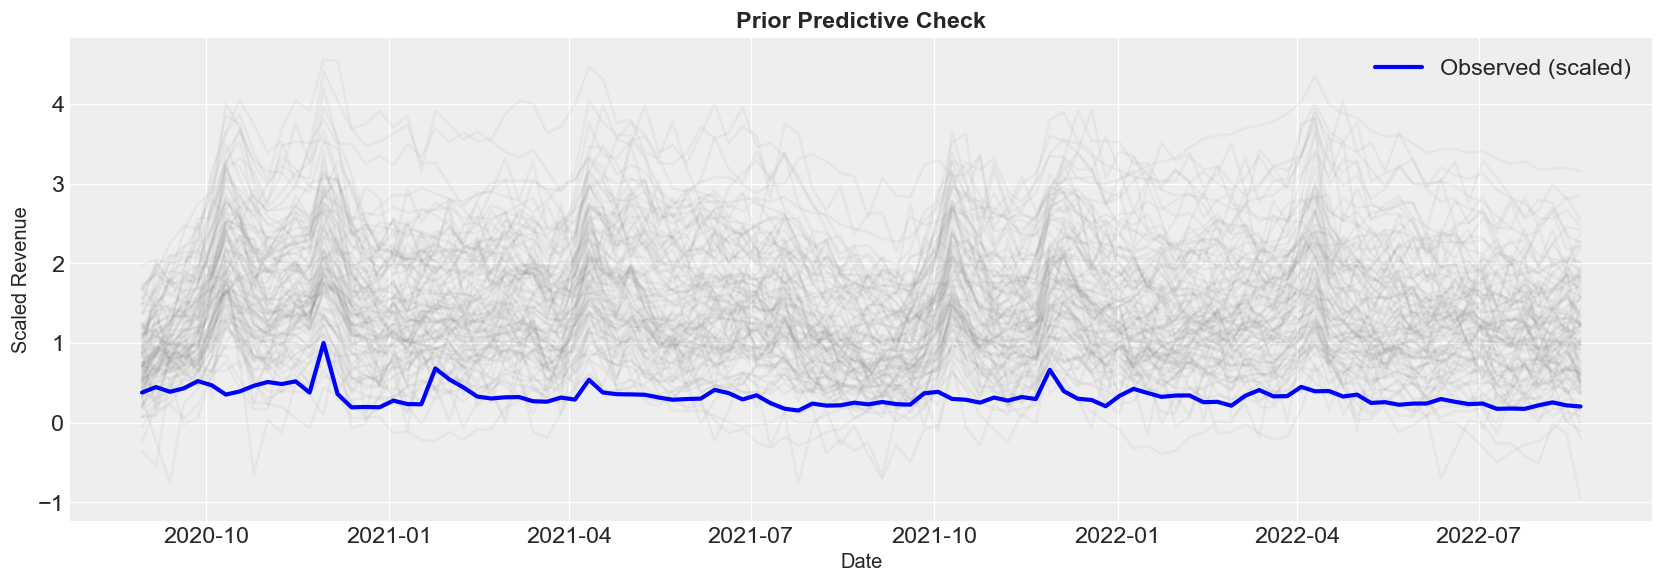

In [13]:
with mmm:
    prior_pred = pm.sample_prior_predictive(draws=500, random_seed=RANDOM_SEED)

# Plot
fig, ax = plt.subplots(figsize=(14, 5))

y_prior = prior_pred.prior_predictive['revenue_obs'].values  # shape: (1, draws, T)
# Flatten chains and draws
y_prior_flat = y_prior.reshape(-1, n_obs)  # shape: (draws, T)

ax.plot(df['start_of_week'], y_prior_flat[:100].T, color='gray', alpha=0.08)
ax.plot(df['start_of_week'], df_model['revenue'], color='blue', linewidth=2.5, label='Observed (scaled)')
ax.set_title('Prior Predictive Check', fontweight='bold')
ax.set_xlabel('Date'); ax.set_ylabel('Scaled Revenue')
ax.legend()
plt.tight_layout(); plt.show()


**Prior predictive interpretation:** The grey lines show 100 revenue trajectories simulated from the priors alone. They range from roughly -0.5 to +2.5 in scaled units and cover the observed blue series. This suggests that the priors are broad enough to accommodate the data without being so wide that they are likely to create sampling difficulties.


# 9. Sample from the posterior

The model is sampled with NUTS using four chains, 1,500 tuning iterations, and 2,000 draws per chain. The `target_accept` value is set to 0.92 to help with the complex sampling geometry introduced by the `pt.scan` adstock transformation.


In [14]:
with mmm:
    trace = pm.sample(
        draws=2000,
        tune=1500,
        chains=4,
        target_accept=0.92,
        random_seed=RANDOM_SEED,
        idata_kwargs={'log_likelihood': True},
    )


Initializing NUTS using jitter+adapt_diag...
C:\Users\vijay\AppData\Local\Programs\Python\Python312\Lib\site-packages\pytensor\tensor\rewriting\elemwise.py:1004: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, beta_trend, beta_fourier, beta_channel, alpha_channel, sigma]


Output()

C:\Users\vijay\AppData\Local\Programs\Python\Python312\Lib\site-packages\pymc\sampling\mcmc.py:1163: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_500 tune and 2_000 draw iterations (6_000 + 8_000 draws total) took 129 seconds.


There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


# 10. Review sampling diagnostics

Check convergence and sampling quality before interpreting the model estimates:

1. **Trace plots:** Look for stationary, well-mixed chains with substantial overlap.
2. **$\hat{R}$:** Values should be below 1.05 for all parameters.
3. **Effective sample size (ESS):** Bulk and tail ESS should each exceed 400.
4. **Divergences:** The target is zero divergent transitions.
5. **Energy plot:** The marginal and transition energy distributions should overlap.


In [15]:
# Divergence count
n_divergent = int(trace.sample_stats['diverging'].sum().values)
print(f"\n{'='*50}")
print(f"DIVERGENCES: {n_divergent}")
print(f"{'='*50}")
if n_divergent > 0:
    print("WARNING: Divergent transitions detected. Consider increasing target_accept or reparameterising.")
else:
    print("No divergences detected. Sampling geometry is healthy.")



DIVERGENCES: 2


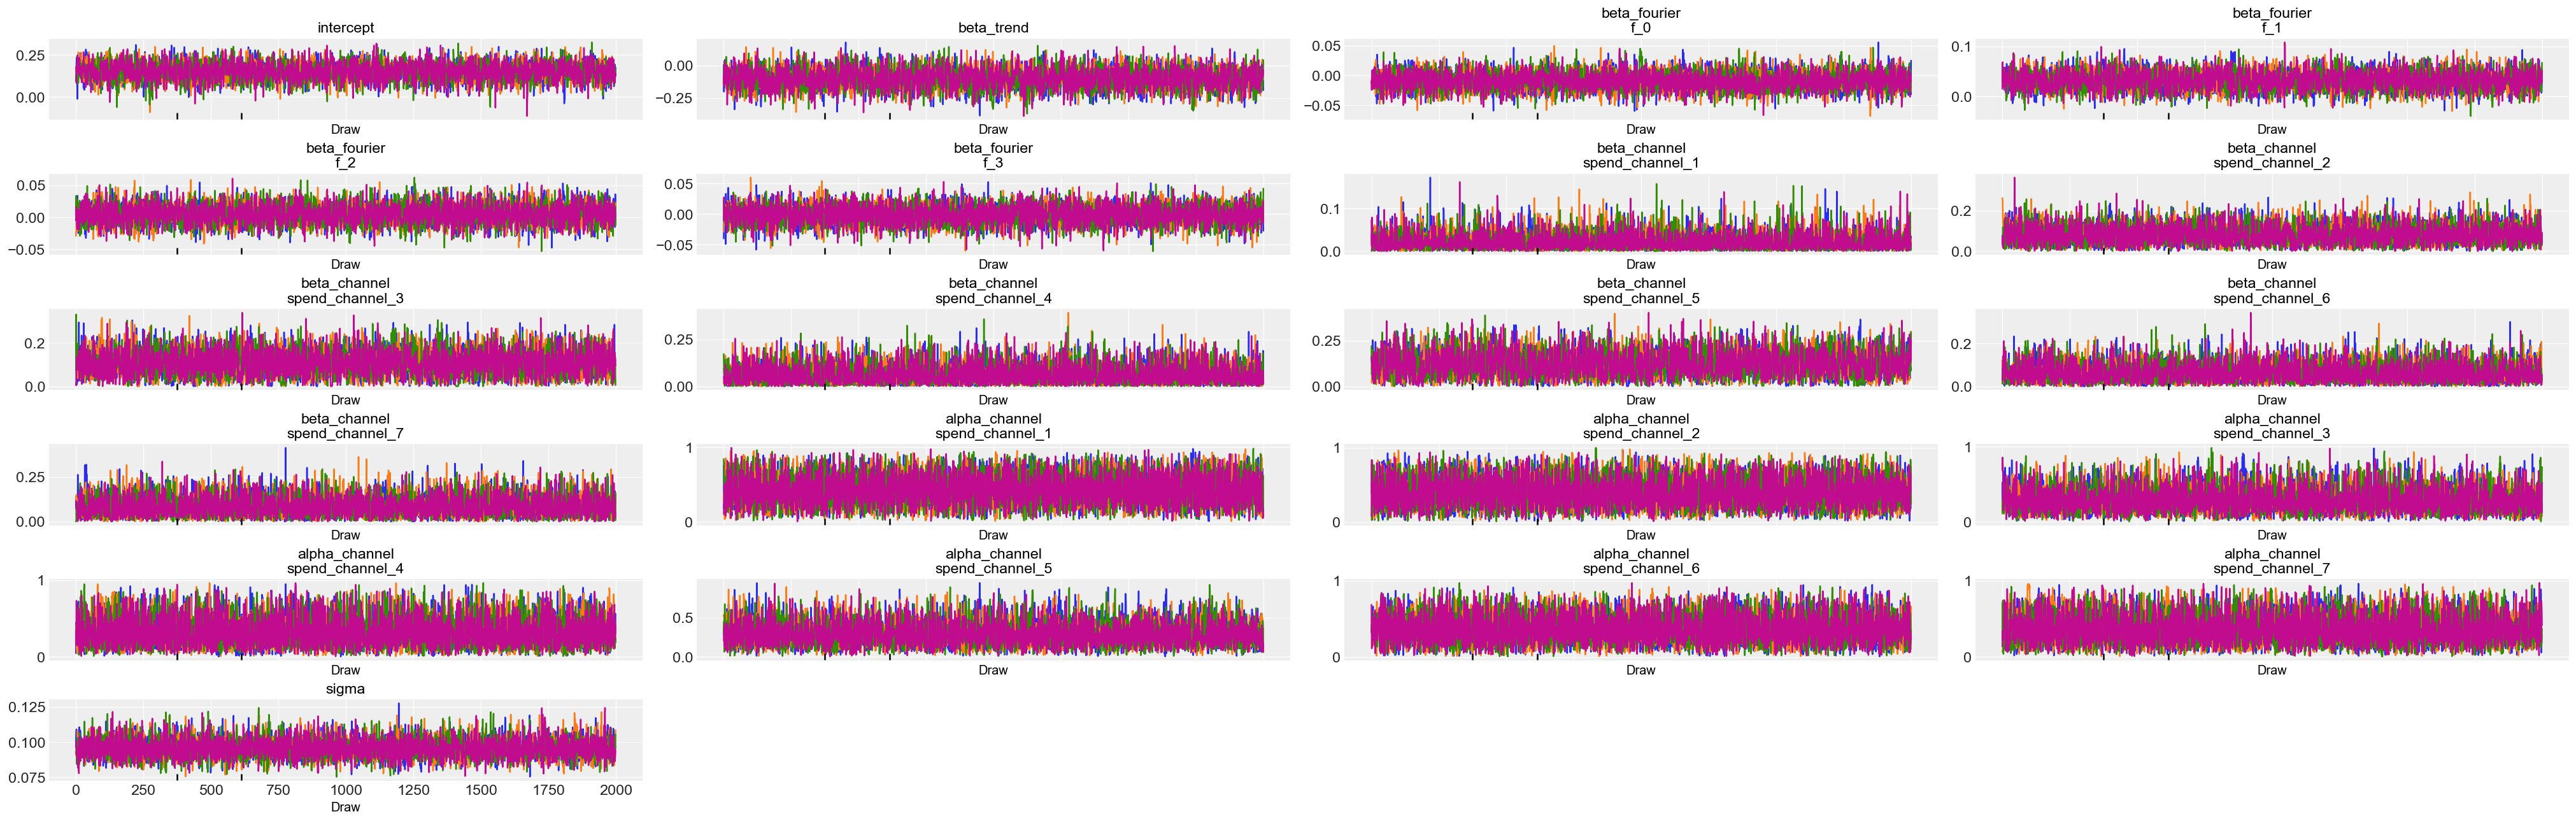

In [16]:
# Trace plots for ALL model parameters
az.plot_trace(trace, var_names=['intercept', 'beta_trend', 'beta_fourier',
                                'beta_channel', 'alpha_channel', 'sigma'])
plt.show()


In [17]:
# Summary table with convergence metrics
summary = az.summary(trace, var_names=['intercept', 'beta_trend', 'beta_fourier',
                                        'beta_channel', 'alpha_channel', 'sigma'],
                     ci_prob=0.94, ci_kind='hdi')
display(summary)


,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,0.153,0.054,0.048,0.25,4276,5365,1.00,0.00083,0.0006
beta_trend,-0.102,0.08,-0.25,0.048,4237,4927,1.00,0.0012,0.00087
beta_fourier[f_0],-0.0091,0.0156,-0.037,0.021,7342,5667,1.00,0.00018,0.00013
beta_fourier[f_1],0.0318,0.019,-0.0036,0.068,4809,5530,1.00,0.00027,0.00019
beta_fourier[f_2],0.0053,0.0157,-0.024,0.036,6941,5350,1.00,0.00019,0.00013
beta_fourier[f_3],-0.0011,0.0161,-0.031,0.029,7636,6235,1.00,0.00018,0.00013
beta_channel[spend_channel_1],0.0211,0.0205,0.00076,0.072,6429,3690,1.00,0.00021,0.00028
beta_channel[spend_channel_2],0.081,0.0487,0.0082,0.18,5256,3673,1.00,0.0006,0.00045
beta_channel[spend_channel_3],0.105,0.06,0.0083,0.23,4067,2997,1.00,0.00085,0.00057
beta_channel[spend_channel_4],0.059,0.053,0.0017,0.18,5355,3951,1.00,0.00064,0.00061


C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\3563740222.py:4: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


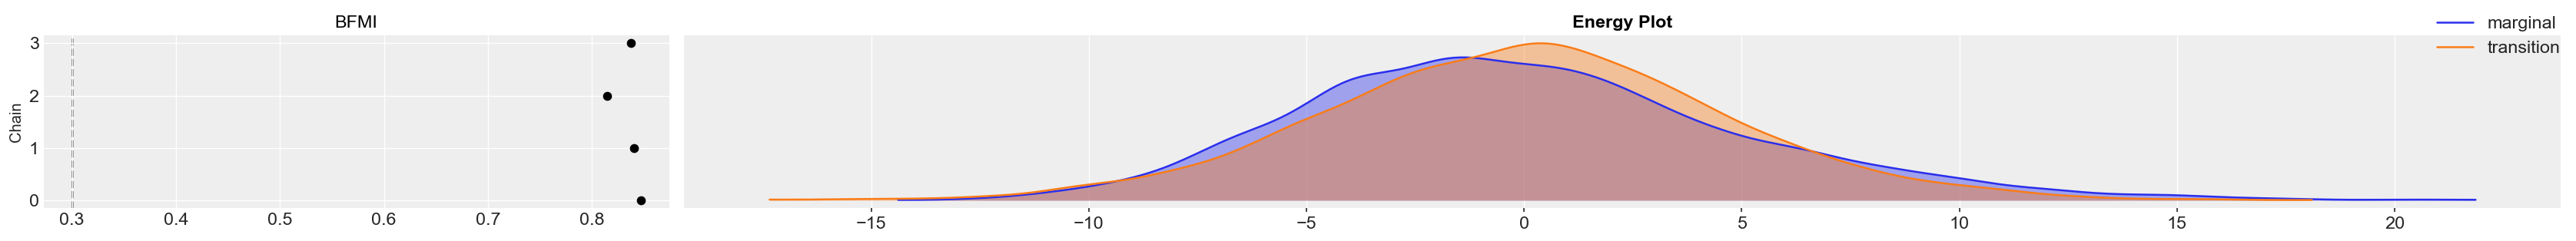

In [18]:
# Energy plot
az.plot_energy(trace)
plt.title('Energy Plot', fontweight='bold')
plt.tight_layout(); plt.show()


**How to interpret the diagnostics**

- **Trace plots:** The four chains should overlap and remain stationary. A chain that gets stuck suggests poor mixing.
- **$\hat{R}$:** Values at or below 1.01 indicate strong convergence. Values above 1.05 are a warning sign.
- **ESS:** Bulk ESS above 400 supports stable posterior mean estimates; tail ESS above 400 supports reliable credible interval boundaries.
- **Energy:** Close overlap between the marginal energy and energy transition distributions suggests the sampler explored the posterior effectively.
- **Divergences:** Zero divergences indicates that no problematic posterior curvature was encountered by the sampler.

If the diagnostics meet these checks, the posterior estimates can be interpreted with greater confidence.


# 11. Check posterior predictions

Posterior predictive sampling is used to assess model fit. Two quantities serve different purposes:

- **Deterministic mean `mu`:** Used for R², RMSE, and residual calculations. It represents uncertainty in the estimated mean, without observation noise.
- **Posterior predictive `revenue_obs`:** Includes observation noise as well as parameter uncertainty. It is used in the visual predictive check to assess whether the model can reproduce the observed data.


Sampling: [revenue_obs]


Output()

C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\963933997.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  revenue_max = float(y_scaler.scale_)   # MaxAbsScaler stores the scaling factor
C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\963933997.py:35: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


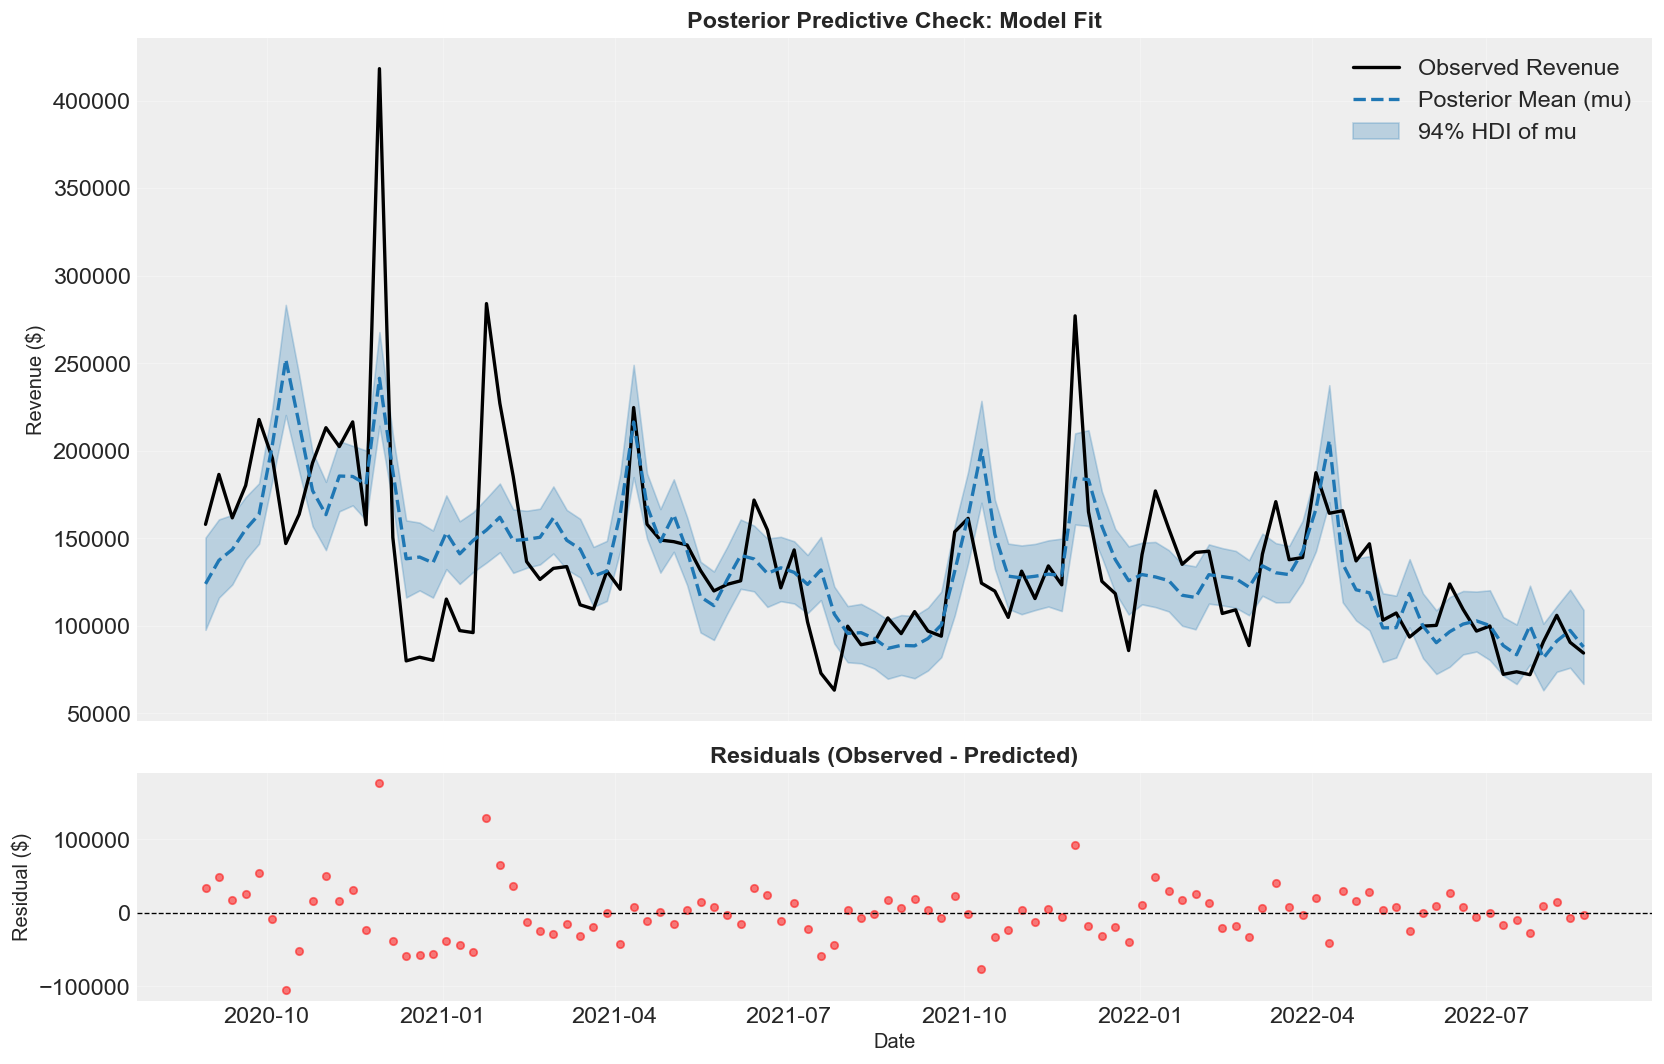

In [19]:
with mmm:
    post_pred = pm.sample_posterior_predictive(trace, random_seed=RANDOM_SEED)

# --- Extract deterministic mu from the trace (fix M6) ---
mu_samples = trace.posterior['mu'].stack(sample=("chain", "draw")).values  # shape (T, n_samples)
mu_mean_scaled = mu_samples.mean(axis=1)
mu_hdi = az.hdi(trace, group='posterior', var_names=['mu'])['mu'].values  # shape (T, 2)

# Unscale to dollars
revenue_max = float(y_scaler.scale_)   # MaxAbsScaler stores the scaling factor
mu_mean_dollars = mu_mean_scaled * revenue_max
mu_hdi_lower = mu_hdi[:, 0] * revenue_max
mu_hdi_upper = mu_hdi[:, 1] * revenue_max
y_true = df['revenue'].values

# --- Plot ---
fig, axes = plt.subplots(2, 1, figsize=(14, 9), height_ratios=[3, 1], sharex=True)

# Top: Fit
axes[0].plot(df['start_of_week'], y_true, 'k-', linewidth=2, label='Observed Revenue')
axes[0].plot(df['start_of_week'], mu_mean_dollars, '--', color='#1f77b4', linewidth=2, label='Posterior Mean (mu)')
axes[0].fill_between(df['start_of_week'], mu_hdi_lower, mu_hdi_upper,
                      color='#1f77b4', alpha=0.25, label='94% HDI of mu')
axes[0].set_title('Posterior Predictive Check: Model Fit', fontweight='bold')
axes[0].set_ylabel('Revenue ($)'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Bottom: Residuals
residuals = y_true - mu_mean_dollars
axes[1].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[1].scatter(df['start_of_week'], residuals, color='red', alpha=0.5, s=20)
axes[1].set_title('Residuals (Observed - Predicted)', fontweight='bold')
axes[1].set_ylabel('Residual ($)'); axes[1].set_xlabel('Date')
axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()


**Posterior predictive interpretation:** The posterior mean follows the observed revenue pattern, and the 94% HDI band shows the range of estimated mean values. The residuals appear scattered around zero without an obvious trend, changing variance, or autocorrelation. This suggests that the model captures much of the structure in the series.


# 12. Evaluate model performance

Calculate the standard regression metrics using the **deterministic posterior mean**, rather than the noisy posterior predictive samples. Metrics are reported on the original dollar scale.


In [20]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

r2   = r2_score(y_true, mu_mean_dollars)
rmse = np.sqrt(mean_squared_error(y_true, mu_mean_dollars))
mae  = mean_absolute_error(y_true, mu_mean_dollars)
mape = mean_absolute_percentage_error(y_true, mu_mean_dollars)

metrics = pd.DataFrame({
    'Metric': ['R\u00b2', 'RMSE', 'MAE', 'MAPE'],
    'Value': [f'{r2:.4f}', f'${rmse:,.0f}', f'${mae:,.0f}', f'{mape:.2%}']
})
display(metrics)

print(f"\nThe model explains {r2:.1%} of the variance in weekly revenue.")
print(f"On average, predictions are off by ${mae:,.0f} ({mape:.1%} of actual).")


,Metric,Value
0,R²,0.4476
1,RMSE,"$37,583"
2,MAE,"$26,328"
3,MAPE,19.60%



The model explains 44.8% of the variance in weekly revenue.
On average, predictions are off by $26,328 (19.6% of actual).


## 12a. Compare model specifications with LOO-CV

Model comparison checks whether the more complex specification improves predictive performance. The notebook compares two models using Leave-One-Out Cross-Validation (LOO-CV) with Pareto-Smoothed Importance Sampling (PSIS):

| Model | Description |
|---|---|
| **Full (Adstock)** | Geometric adstock with learnable decay rates. |
| **Baseline (No Adstock)** | The same general structure, using raw spend without carry-over. |

If adstock captures useful carry-over information, the full model should have a better expected log predictive density (ELPD) than the baseline.


In [21]:
# --- Define and fit a baseline model (no adstock) ---
with pm.Model(coords=coords) as mmm_baseline:
    intercept_b   = pm.Normal("intercept", mu=0.3, sigma=0.3)
    beta_trend_b  = pm.Normal("beta_trend", mu=0, sigma=0.2)
    beta_fourier_b = pm.Normal("beta_fourier", mu=0, sigma=0.2, dims="fourier")
    beta_channel_b = pm.HalfNormal("beta_channel", sigma=0.3, dims="channel")
    sigma_b       = pm.HalfNormal("sigma", sigma=0.15)

    trend_b    = beta_trend_b * df_model['t'].values
    season_b   = pm.math.dot(fourier_features, beta_fourier_b)
    # No adstock - raw scaled spend dotted with coefficients
    media_b    = pm.math.dot(pt.as_tensor_variable(df_model[spend_cols].values), beta_channel_b)

    mu_b = pm.Deterministic("mu", intercept_b + trend_b + season_b + media_b)
    obs_b = pm.Normal("revenue_obs", mu=mu_b, sigma=sigma_b,
                       observed=df_model['revenue'].values)

with mmm_baseline:
    trace_baseline = pm.sample(
        draws=1000, tune=1000, chains=4,
        target_accept=0.9, random_seed=RANDOM_SEED,
        idata_kwargs={'log_likelihood': True},
    )

print("Baseline model sampled successfully.")
n_div_base = int(trace_baseline.sample_stats['diverging'].sum().values)
print(f"Baseline divergences: {n_div_base}")


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, beta_trend, beta_fourier, beta_channel, sigma]


Output()

C:\Users\vijay\AppData\Local\Programs\Python\Python312\Lib\site-packages\pymc\sampling\mcmc.py:1163: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 17 seconds.


Baseline model sampled successfully.
Baseline divergences: 0


C:\Users\vijay\AppData\Local\Programs\Python\Python312\Lib\site-packages\arviz_stats\loo\helper_loo.py:1146: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
C:\Users\vijay\AppData\Local\Programs\Python\Python312\Lib\site-packages\arviz_stats\loo\helper_loo.py:1146: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Baseline (No Adstock),0,0.0,0.0,NaN,,2 k̂ > 0.70,16.4,90.0,15.0,0.95
Full (Adstock),1,-3.0,2.7,0.9,|elpd_diff| < 4,3 k̂ > 0.70,16.6,90.0,16.0,0.05


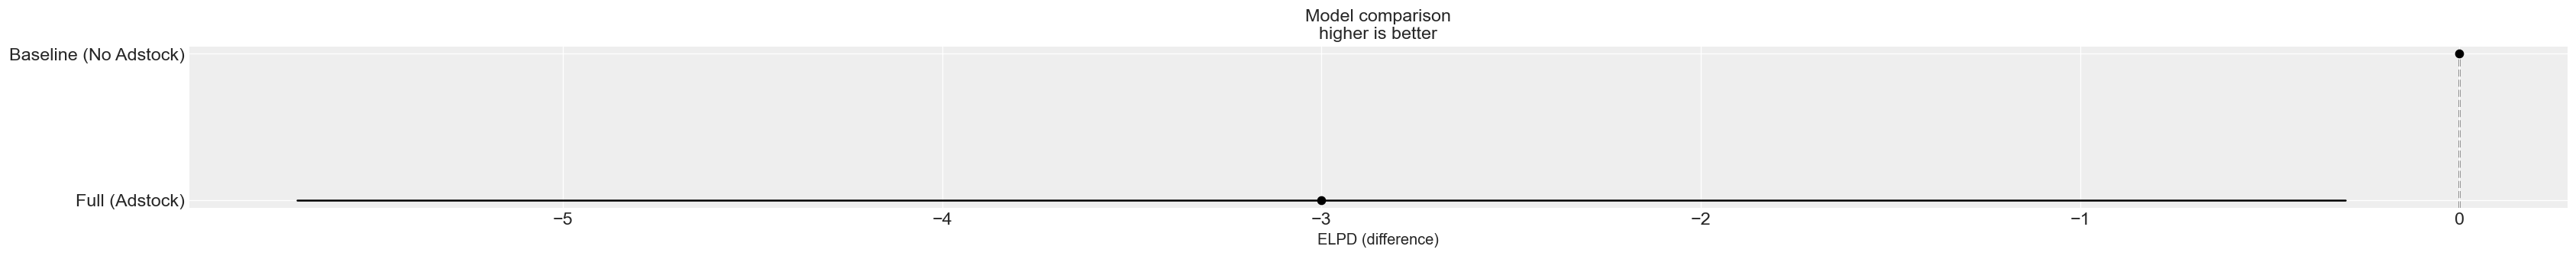

In [22]:
# --- LOO-CV Comparison ---
comparison = az.compare(
    {"Full (Adstock)": trace, "Baseline (No Adstock)": trace_baseline},
    
)
display(comparison)

az.plot_compare(comparison)
plt.show()


**How to read the model comparison table**

- **`rank`:** 0 indicates the best-ranked model.
- **`elpd_loo`:** Expected log pointwise predictive density; higher (less negative) values are better.
- **`d_elpd`:** Difference from the best model; `dse` is the standard error of that difference and helps assess whether it is meaningful.
- **`p_loo`:** Estimated effective number of model parameters. A more complex model that does not improve ELPD may be overfitting.
- **`warning`:** Indicates that some Pareto-$k$ values exceed 0.7, suggesting observations that are difficult to predict and may affect the LOO estimate.

If the full model ranks first and its ELPD advantage is greater than about twice the standard error, that is stronger evidence that modeling carry-over improves predictive accuracy beyond in-sample fit.


# 13. Estimate channel contributions

For every posterior draw of $\alpha_c$ and $\beta_c$, replay the adstock calculation in NumPy using the observed spend history. This applies the same recursive transformation used during model fitting to the actual channel data.

A steady-state approximation such as $\frac{\text{Spend}}{1-\alpha}$ is not used because it assumes constant spend over time, while the observed spend varies by week.


In [23]:
# Extract posterior samples
beta_post  = trace.posterior['beta_channel'].stack(sample=("chain", "draw")).values   # (7, S)
alpha_post = trace.posterior['alpha_channel'].stack(sample=("chain", "draw")).values  # (7, S)
n_channels = len(spend_cols)
n_samples  = beta_post.shape[1]

# Replay adstock for each posterior sample (fix C1)
contribution_scaled = np.zeros((n_channels, n_samples))
for c in range(n_channels):
    x_c = df_model[spend_cols[c]].values  # scaled spend vector, length T
    for s in range(n_samples):
        adstocked = adstock_numpy(x_c, alpha_post[c, s])
        contribution_scaled[c, s] = beta_post[c, s] * adstocked.sum()

# Convert to dollars
contribution_dollars = contribution_scaled * revenue_max

# Summary table
contrib_records = []
for c, col in enumerate(spend_cols):
    hdi = az.hdi(contribution_dollars[c, :], prob=0.94)
    contrib_records.append({
        'Channel': col.replace('spend_channel_', 'Channel '),
        'Mean ($)': np.mean(contribution_dollars[c, :]),
        '94% HDI Lower ($)': hdi[0],
        '94% HDI Upper ($)': hdi[1],
    })
contrib_df = pd.DataFrame(contrib_records).sort_values('Mean ($)', ascending=False)
display(contrib_df.style.format({'Mean ($)': '${:,.0f}', '94% HDI Lower ($)': '${:,.0f}', '94% HDI Upper ($)': '${:,.0f}'}))


,Channel,Mean ($),94% HDI Lower ($),94% HDI Upper ($)
2,Channel 3,"$2,509,830",$643,"$4,630,662"
6,Channel 7,"$2,012,486",$617,"$4,314,150"
4,Channel 5,"$1,883,952","$6,813","$3,554,248"
1,Channel 2,"$1,313,909","$25,886","$2,537,317"
3,Channel 4,"$1,133,430",$109,"$2,711,124"
5,Channel 6,"$658,580",$383,"$1,436,288"
0,Channel 1,"$264,685",$16,"$726,091"


C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\4069443521.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=plot_data_melted, y='Channel', x='Contribution ($)',
C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\4069443521.py:14: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


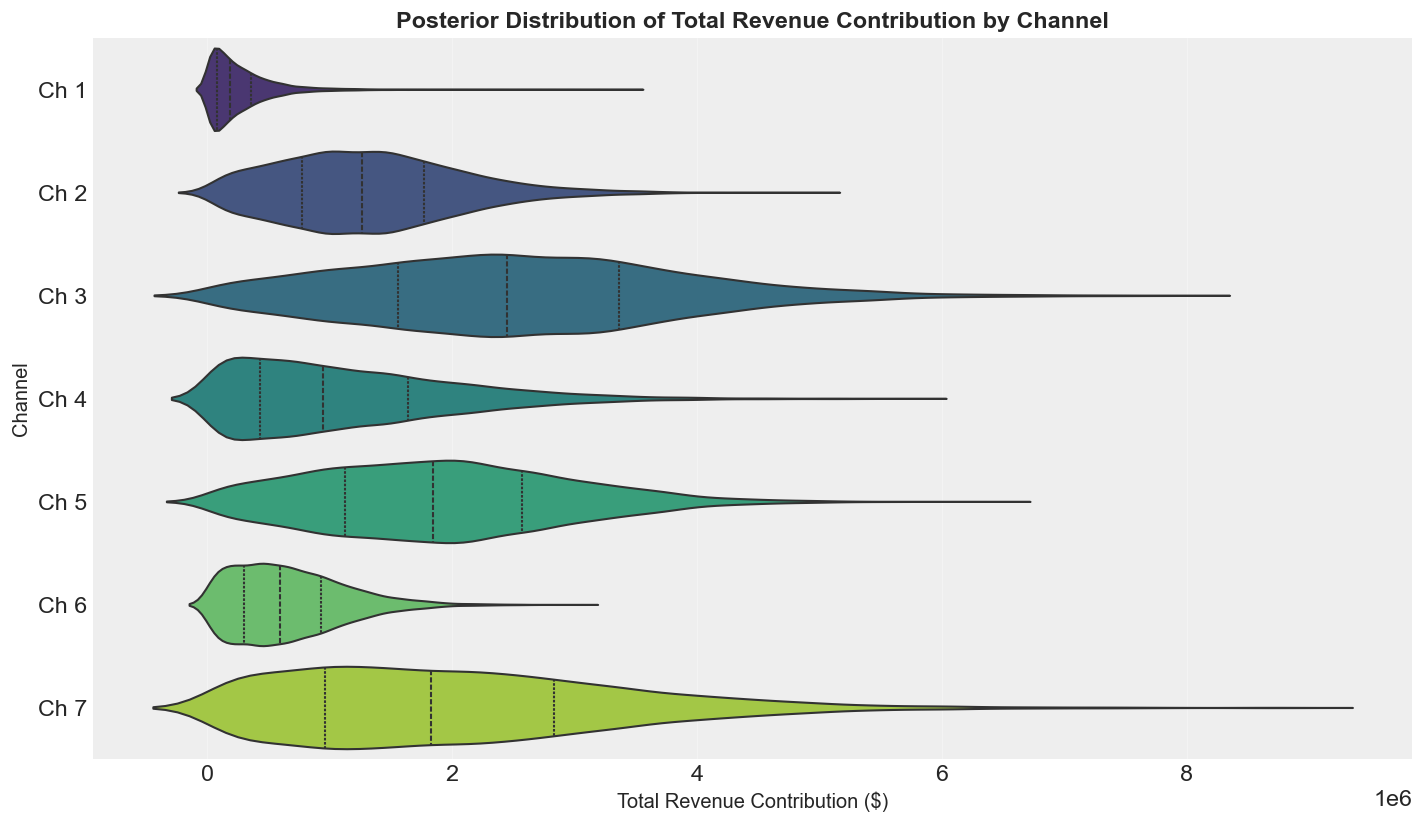

In [24]:
# Violin plot of contribution distributions
fig, ax = plt.subplots(figsize=(12, 7))
plot_data = pd.DataFrame({
    col.replace('spend_channel_', 'Ch '): contribution_dollars[c, :]
    for c, col in enumerate(spend_cols)
})
plot_data_melted = plot_data.melt(var_name='Channel', value_name='Contribution ($)')

sns.violinplot(data=plot_data_melted, y='Channel', x='Contribution ($)',
               orient='h', palette='viridis', inner='quartile', ax=ax)
ax.set_title('Posterior Distribution of Total Revenue Contribution by Channel', fontweight='bold')
ax.set_xlabel('Total Revenue Contribution ($)')
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout(); plt.show()


## 13a. Decompose revenue over time

A central MMM output is a time-based decomposition of revenue into baseline factors (intercept, trend, and seasonality) and estimated channel contributions. Since these components were stored as `pm.Deterministic` variables, their posterior means can be extracted from the trace.


C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\4152706124.py:36: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


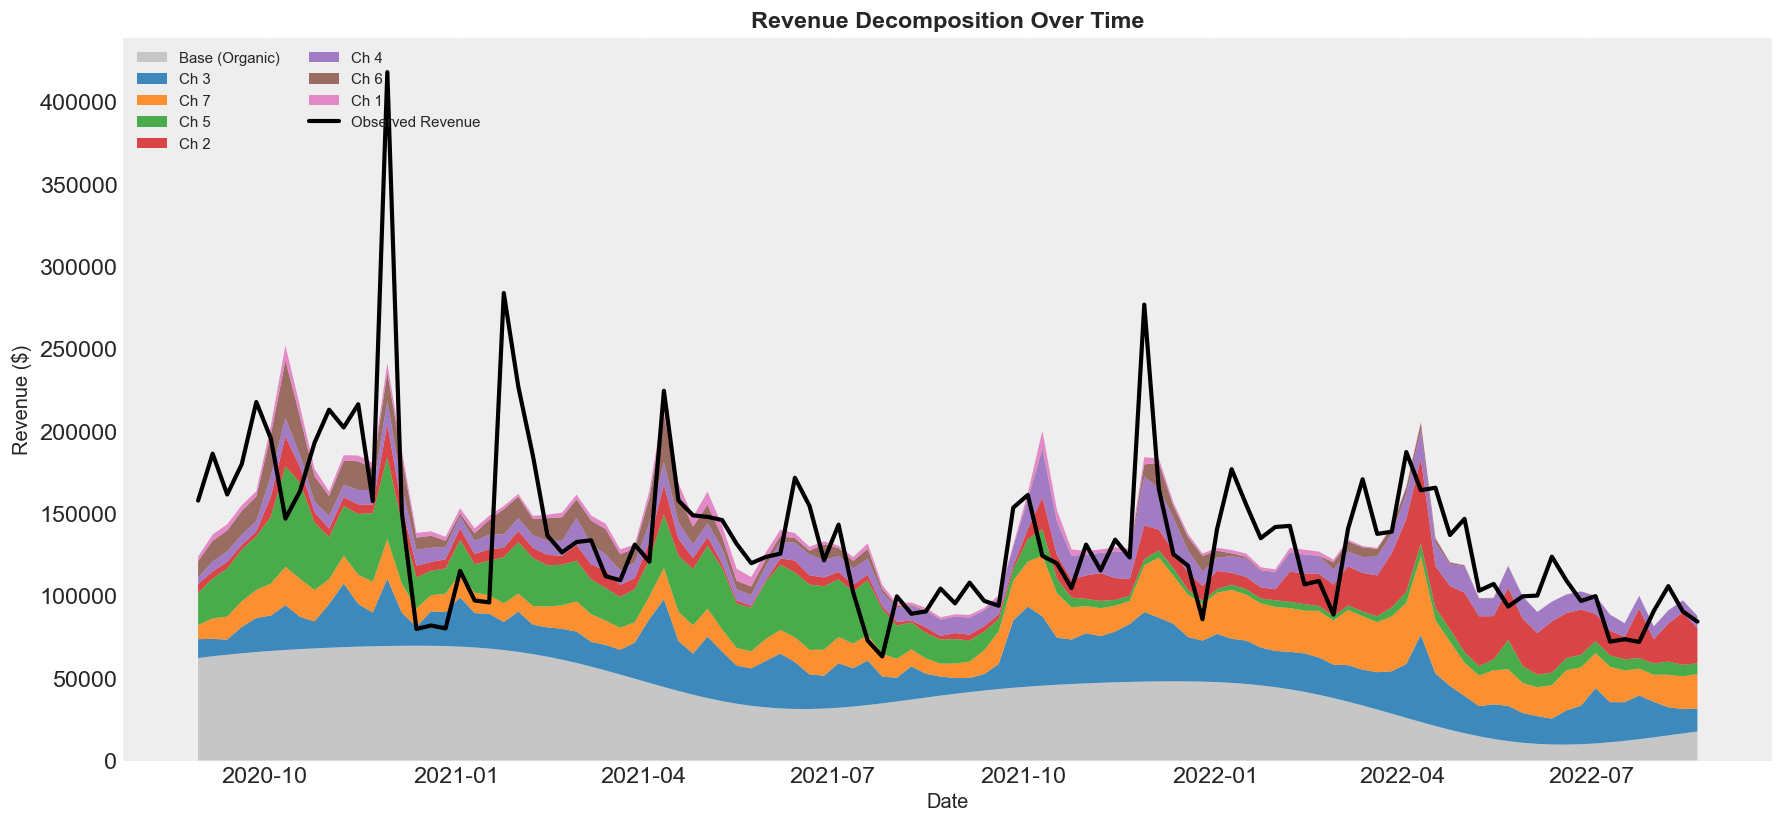

Total Base (Organic):   $   4,425,126  ( 31.2%)
  Channel 3       : $   2,509,830  ( 17.7%)
  Channel 7       : $   2,012,486  ( 14.2%)
  Channel 5       : $   1,883,952  ( 13.3%)
  Channel 2       : $   1,313,909  (  9.3%)
  Channel 4       : $   1,133,430  (  8.0%)
  Channel 6       : $     658,580  (  4.6%)
  Channel 1       : $     264,685  (  1.9%)
Total Media:            $   9,776,871  ( 68.8%)


In [25]:
# --- Extract posterior means for each component ---
intercept_pm = float(trace.posterior['intercept'].mean())
trend_pm     = trace.posterior['trend'].mean(dim=("chain", "draw")).values
season_pm    = trace.posterior['seasonality'].mean(dim=("chain", "draw")).values

base_dollars = (intercept_pm + trend_pm + season_pm) * revenue_max

# Per-channel contributions over time
channel_ts_dollars = {}
for col in spend_cols:
    channel_ts_dollars[col] = trace.posterior[f'contrib_{col}'].mean(dim=("chain", "draw")).values * revenue_max

# Order channels by total contribution (largest at bottom for stable stacking)
channel_totals = {col: vals.sum() for col, vals in channel_ts_dollars.items()}
sorted_channels = sorted(channel_totals, key=channel_totals.get, reverse=True)

# Build stacking arrays
stack_data   = [base_dollars]
stack_labels = ['Base (Organic)']
stack_colors = ['#c0c0c0']  # grey for base
cmap = plt.cm.tab10
for j, col in enumerate(sorted_channels):
    stack_data.append(channel_ts_dollars[col])
    stack_labels.append(col.replace('spend_channel_', 'Ch '))
    stack_colors.append(cmap(j))

# --- Stacked area plot ---
fig, ax = plt.subplots(figsize=(15, 7))
ax.stackplot(df['start_of_week'], *stack_data, labels=stack_labels, colors=stack_colors, alpha=0.85)
ax.plot(df['start_of_week'], y_true, 'k-', linewidth=2.5, label='Observed Revenue')
ax.set_title('Revenue Decomposition Over Time', fontweight='bold', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Revenue ($)')
ax.legend(loc='upper left', fontsize=9, ncol=2)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# --- Contribution share summary ---
total_base = base_dollars.sum()
total_media = sum(v.sum() for v in channel_ts_dollars.values())
total_mu = total_base + total_media
print(f"Total Base (Organic):   ${total_base:>12,.0f}  ({total_base/total_mu:>6.1%})")
for col in sorted_channels:
    t = channel_ts_dollars[col].sum()
    print(f"  {col.replace('spend_channel_', 'Channel '):<16s}: ${t:>12,.0f}  ({t/total_mu:>6.1%})")
print(f"Total Media:            ${total_media:>12,.0f}  ({total_media/total_mu:>6.1%})")


**Reading the decomposition chart:** The stacked area chart shows the model's estimated components over time alongside observed revenue in black. The grey base layer represents baseline revenue, and each coloured band represents the estimated contribution associated with one channel.

The chart helps identify which channels contribute most at different points in time, how channel contributions vary seasonally, and how far the model's total estimate is from observed revenue. That gap is the model residual.


# 14. Calculate return on investment

Channel ROI is defined as:

$$\text{ROI}_c = \frac{\text{Total revenue contribution from channel } c}{\text{Total raw spend on channel } c}$$

The numerator is estimated from the posterior and the denominator comes from the observed spend data. Repeating the calculation across posterior draws carries model uncertainty into the ROI estimates.

**Assumptions**

- ROI covers the full two-year period.
- Raw, unscaled dollar spend is used in the denominator.
- An ROI of 2.0x means an estimated $2 in revenue contribution for each $1 spent.


In [26]:
total_raw_spend = df[spend_cols].sum(axis=0).values  # shape (7,)

roi_samples = np.zeros((n_channels, n_samples))
for c in range(n_channels):
    roi_samples[c, :] = contribution_dollars[c, :] / total_raw_spend[c]

# Summary table
roi_records = []
for c, col in enumerate(spend_cols):
    hdi = az.hdi(roi_samples[c, :], prob=0.94)
    roi_records.append({
        'Channel': col.replace('spend_channel_', 'Channel '),
        'Mean ROI': np.mean(roi_samples[c, :]),
        '94% HDI Lower': hdi[0],
        '94% HDI Upper': hdi[1],
        'Total Spend ($)': total_raw_spend[c],
    })
roi_df = pd.DataFrame(roi_records).sort_values('Mean ROI', ascending=False)
display(roi_df.style.format({
    'Mean ROI': '{:.2f}x',
    '94% HDI Lower': '{:.2f}x',
    '94% HDI Upper': '{:.2f}x',
    'Total Spend ($)': '${:,.0f}',
}))


,Channel,Mean ROI,94% HDI Lower,94% HDI Upper,Total Spend ($)
1,Channel 2,36.76x,0.72x,71.00x,"$35,739"
4,Channel 5,2.11x,0.01x,3.99x,"$891,864"
0,Channel 1,2.04x,0.00x,5.61x,"$129,543"
3,Channel 4,1.58x,0.00x,3.77x,"$719,174"
5,Channel 6,1.25x,0.00x,2.73x,"$526,625"
2,Channel 3,1.24x,0.00x,2.28x,"$2,028,747"
6,Channel 7,0.70x,0.00x,1.50x,"$2,880,942"


C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\1558161469.py:18: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


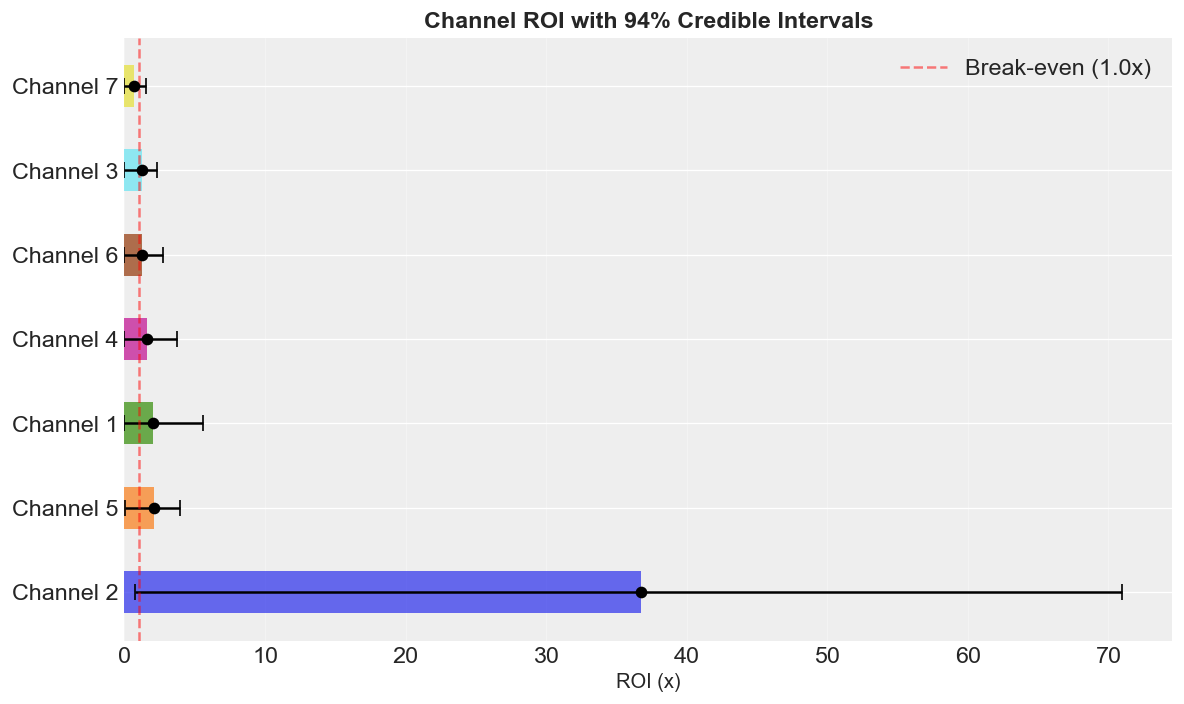

In [27]:
# ROI forest plot
fig, ax = plt.subplots(figsize=(10, 6))
sorted_idx = roi_df.index
for i, (_, row) in enumerate(roi_df.iterrows()):
    ax.barh(i, row['Mean ROI'], color=f'C{i}', alpha=0.7, height=0.5)
    ax.errorbar(row['Mean ROI'], i,
                xerr=[[row['Mean ROI'] - row['94% HDI Lower']],
                      [row['94% HDI Upper'] - row['Mean ROI']]],
                fmt='o', color='black', capsize=5)

ax.set_yticks(range(len(roi_df)))
ax.set_yticklabels(roi_df['Channel'].values)
ax.set_xlabel('ROI (x)')
ax.set_title('Channel ROI with 94% Credible Intervals', fontweight='bold')
ax.axvline(1.0, color='red', linestyle='--', alpha=0.5, label='Break-even (1.0x)')
ax.legend()
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout(); plt.show()


## 14a. Simulate a budget reallocation

The scenario shifts 20% of the weekly budget from the channel with the lowest estimated ROI to the channel with the highest. Posterior draws are used to estimate a range of possible revenue changes, carrying uncertainty through the simulation.

**Important limitation:** The model assumes a linear relationship between spend and revenue and does not include saturation curves. Since real channels can have diminishing marginal returns, the estimated gain may be an upper bound. Validate the scenario with a controlled geo-holdout experiment before making a large budget commitment.


In [28]:
# --- Identify best and worst ROI channels ---
ch_name_to_col = {col.replace('spend_channel_', 'Channel '): col for col in spend_cols}
best_ch_name  = roi_df.iloc[0]['Channel']
worst_ch_name = roi_df.iloc[-1]['Channel']
best_col_sim  = ch_name_to_col[best_ch_name]
worst_col_sim = ch_name_to_col[worst_ch_name]
best_idx  = spend_cols.index(best_col_sim)
worst_idx = spend_cols.index(worst_col_sim)

# --- Scenario: shift 20% of worst channel's weekly spend to best ---
SHIFT_FRACTION = 0.20

spend_worst_orig = df[worst_col_sim].values
spend_best_orig  = df[best_col_sim].values
dollar_shift     = SHIFT_FRACTION * spend_worst_orig  # per-week shift

spend_worst_new = spend_worst_orig - dollar_shift
spend_best_new  = spend_best_orig  + dollar_shift

# Scale using the fitted MaxAbsScaler
spend_worst_new_scaled = spend_worst_new / X_scaler.scale_[worst_idx]
spend_best_new_scaled  = spend_best_new  / X_scaler.scale_[best_idx]

# --- Simulate revenue change for each posterior sample ---
n_sim = min(n_samples, 2000)
revenue_change = np.zeros(n_sim)

for s in range(n_sim):
    # Old contributions (original spend)
    old_worst = beta_post[worst_idx, s] * adstock_numpy(df_model[worst_col_sim].values, alpha_post[worst_idx, s]).sum()
    old_best  = beta_post[best_idx, s]  * adstock_numpy(df_model[best_col_sim].values,  alpha_post[best_idx, s]).sum()

    # New contributions (reallocated spend)
    new_worst = beta_post[worst_idx, s] * adstock_numpy(spend_worst_new_scaled, alpha_post[worst_idx, s]).sum()
    new_best  = beta_post[best_idx, s]  * adstock_numpy(spend_best_new_scaled,  alpha_post[best_idx, s]).sum()

    revenue_change[s] = ((new_worst - old_worst) + (new_best - old_best)) * revenue_max

# --- Report results ---
mean_change = np.mean(revenue_change)
hdi_change  = az.hdi(revenue_change, prob=0.94)
total_shifted = dollar_shift.sum()

print(f"{'='*65}")
print(f"SCENARIO: Shift 20% of {worst_ch_name} budget -> {best_ch_name}")
print(f"{'='*65}")
print(f"Total dollars shifted over 2 years: ${total_shifted:,.0f}")
print(f"")
print(f"Expected change in total 2-year revenue:")
print(f"  Posterior mean : ${mean_change:+,.0f}")
print(f"  94% HDI        : [${hdi_change[0]:+,.0f}, ${hdi_change[1]:+,.0f}]")
print(f"")
if mean_change > 0:
    print(f"  -> Reallocation is expected to INCREASE total revenue by ${mean_change:,.0f}")
    print(f"     Reallocation ROI: {mean_change/total_shifted:.2f}x per dollar shifted")
else:
    print(f"  -> Reallocation is expected to DECREASE total revenue by ${abs(mean_change):,.0f}")
    print(f"     The current allocation may already be near-optimal for these two channels.")


SCENARIO: Shift 20% of Channel 7 budget -> Channel 2
Total dollars shifted over 2 years: $576,188

Expected change in total 2-year revenue:
  Posterior mean : $+21,263,383
  94% HDI        : [$+793,595, $+41,768,239]

  -> Reallocation is expected to INCREASE total revenue by $21,263,383
     Reallocation ROI: 36.90x per dollar shifted


C:\Users\vijay\AppData\Local\Temp\ipykernel_33720\4138947685.py:14: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


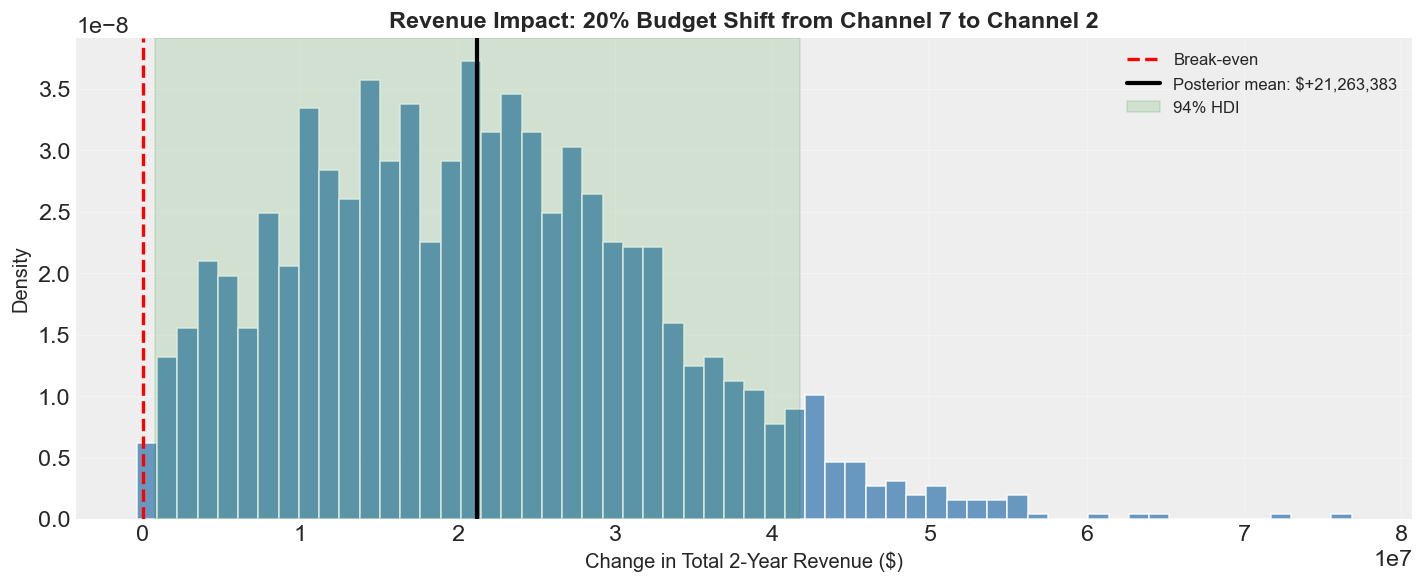

In [29]:
# --- Histogram of simulated revenue impact ---
fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(revenue_change, bins=60, color='steelblue', edgecolor='white', alpha=0.8, density=True)
ax.axvline(0, color='red', linestyle='--', linewidth=2, label='Break-even')
ax.axvline(mean_change, color='black', linestyle='-', linewidth=2.5,
           label=f'Posterior mean: ${mean_change:+,.0f}')
ax.axvspan(hdi_change[0], hdi_change[1], alpha=0.12, color='green', label='94% HDI')
ax.set_title(f'Revenue Impact: 20% Budget Shift from {worst_ch_name} to {best_ch_name}',
             fontweight='bold')
ax.set_xlabel('Change in Total 2-Year Revenue ($)')
ax.set_ylabel('Density')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Interpreting the scenario chart:** The histogram shows the posterior distribution of revenue change under the reallocation. Values to the right of the red break-even line indicate a predicted increase; values to the left indicate a predicted decrease. A wider distribution means greater uncertainty and calls for more caution.

**Key limitation:** Because the model does not include saturation, it cannot estimate diminishing returns as spend rises. The highest-ROI channel may eventually saturate, so the actual gain from reallocation could be smaller than the simulated estimate. Validate the result before making a large-scale budget change.


# 15. Business insights and recommendations

The next cell summarizes findings from the posterior estimates, including the highest and lowest ROI channels, the largest estimated contributor, and channels with high uncertainty.


In [30]:
# Programmatically generate insights from the actual posterior
top_roi = roi_df.iloc[0]
bottom_roi = roi_df.iloc[-1]
top_contrib = contrib_df.iloc[0]

# Channels where HDI includes 0 (uncertain)
uncertain_channels = [r['Channel'] for _, r in pd.DataFrame(contrib_records).iterrows()
                      if r['94% HDI Lower ($)'] <= 0]

print("=" * 70)
print("EXECUTIVE SUMMARY")
print("=" * 70)
print(f"\n1. HIGHEST ROI: {top_roi['Channel']} at {top_roi['Mean ROI']:.2f}x")
print(f"   (94% HDI: {top_roi['94% HDI Lower']:.2f}x - {top_roi['94% HDI Upper']:.2f}x)")
print(f"   -> This channel generates the most revenue per dollar spent.")
print(f"   -> Recommendation: INCREASE investment if saturation allows.")

print(f"\n2. LOWEST ROI: {bottom_roi['Channel']} at {bottom_roi['Mean ROI']:.2f}x")
print(f"   (94% HDI: {bottom_roi['94% HDI Lower']:.2f}x - {bottom_roi['94% HDI Upper']:.2f}x)")
if bottom_roi['Mean ROI'] < 1.0:
    print(f"   -> This channel is BELOW break-even. Every dollar spent destroys value.")
    print(f"   -> Recommendation: REDUCE or PAUSE spend. Run a geo-holdout experiment to confirm.")
else:
    print(f"   -> This channel is profitable but least efficient.")
    print(f"   -> Recommendation: Audit creative and targeting before scaling.")

print(f"\n3. LARGEST ABSOLUTE CONTRIBUTOR: {top_contrib['Channel']}")
print(f"   Mean contribution: ${top_contrib['Mean ($)']:,.0f}")

if uncertain_channels:
    print(f"\n4. HIGH UNCERTAINTY CHANNELS: {', '.join(uncertain_channels)}")
    print(f"   -> The model cannot confidently attribute revenue to these channels.")
    print(f"   -> Recommendation: Run controlled lift experiments (geo-holdout or A/B tests)")
    print(f"      to establish causal ground truth for these channels.")
else:
    print(f"\n4. All channels have credible intervals above zero - the model is")
    print(f"   reasonably confident that each channel contributes positively.")

print(f"\n5. BUDGET REALLOCATION:")
print(f"   Shift budget from the bottom-ranked ROI channels toward the top-ranked ones.")
print(f"   Do this INCREMENTALLY - this model does not include saturation curves,")
print(f"   so we cannot predict diminishing returns at higher spend levels.")


EXECUTIVE SUMMARY

1. HIGHEST ROI: Channel 2 at 36.76x
   (94% HDI: 0.72x - 71.00x)
   -> This channel generates the most revenue per dollar spent.
   -> Recommendation: INCREASE investment if saturation allows.

2. LOWEST ROI: Channel 7 at 0.70x
   (94% HDI: 0.00x - 1.50x)
   -> This channel is BELOW break-even. Every dollar spent destroys value.
   -> Recommendation: REDUCE or PAUSE spend. Run a geo-holdout experiment to confirm.

3. LARGEST ABSOLUTE CONTRIBUTOR: Channel 3
   Mean contribution: $2,509,830

4. All channels have credible intervals above zero - the model is
   reasonably confident that each channel contributes positively.

5. BUDGET REALLOCATION:
   Shift budget from the bottom-ranked ROI channels toward the top-ranked ones.
   Do this INCREMENTALLY - this model does not include saturation curves,
   so we cannot predict diminishing returns at higher spend levels.


# 16. Possible Business Questions

### Question 1: How is advertising carry-over modeled?

Carry-over is represented with **Geometric Adstock**, using the recursive formula:

$$A_t = S_t + \alpha A_{t-1}, \qquad A_0 = S_0$$

Here, $\alpha \in [0,1)$ is the decay or retention rate. This approach reflects the gradual fading of consumer memory, uses one interpretable parameter, and is computationally tractable. Implementing the recursion with `pytensor.scan` allows PyMC's NUTS sampler to estimate $\alpha$ jointly with the other model parameters.

---

### Question 2: Why were these priors selected?

The priors are weakly informative and defined on the MaxAbs-scaled $[0,1]$ range:

- **Channel coefficients**, $\beta_c \sim \text{HalfNormal}(0.3)$, are constrained to be positive. This reflects the assumption that marketing should not reduce revenue and also helps with identifiability: without the constraint, negative channel effects could trade off against a higher intercept.
- **Adstock decay**, $\alpha_c \sim \text{Beta}(2,2)$, is bounded between 0 and 1. Its symmetric shape discourages extreme values, such as no carry-over or near-infinite memory, without specifying a particular decay rate.
- **Noise**, $\sigma \sim \text{HalfNormal}(0.15)$, is positive, and its scale reflects an expectation that residuals may be around 10–15% of the scaled revenue range.
- **Trend and seasonality terms**, with $\text{Normal}(0,0.2)$ priors, can be positive or negative. Their scale leaves room for the data to update the estimates.

---

### Question 3: How do prior and posterior predictive sampling differ?

**Prior predictive sampling** (Section 8) generates revenue trajectories from the priors before using the observed data. The simulated trajectories span a broad range and show whether the priors can accommodate the observed series.

**Posterior predictive sampling** (Section 11) generates predictions after the model has been updated with observed revenue. The predictions track the data more closely and have a narrower 94% HDI, showing how the observations update the prior beliefs. Prior samples describe uncertainty before seeing the data; posterior samples describe uncertainty after learning from it.

---

### Question 4: How well does the model perform?

Section 12 reports performance using the deterministic posterior mean $\mu$ rather than noisy posterior predictive samples:

- **R²** measures the proportion of variation explained by the model.
- **RMSE and MAE** summarize prediction error in dollars.
- **MAPE** expresses error as a percentage of actual revenue.

Section 10 reviews convergence diagnostics, including $\hat{R}$, ESS, and divergences. The residual plot also checks for systematic patterns that might indicate the model has missed trend, seasonality, or media-related structure.

---

### Question 5: What can the model tell us about channel performance?

The posterior contribution estimates in Section 13 show differences in the channels' modeled performance:

- A channel may contribute a large amount of revenue but have moderate ROI if its budget is also large.
- A channel with a smaller budget may have higher estimated ROI but wider credible intervals.
- Multicollinearity can widen posterior intervals because it makes individual channel effects harder to separate.

Channel rankings should not be based on posterior means alone. If credible intervals overlap, the relative ranking may change with different data.

---

### Question 6: How is ROI estimated, and how should channels be ranked?

Section 14 calculates ROI as posterior channel contribution divided by raw spend, using the full posterior distribution. The ranking table and forest plot show mean ROI and 94% HDIs. Overlapping intervals indicate that the data may not clearly distinguish channels. Budget shifts should be incremental because the model does not include saturation and therefore cannot estimate diminishing returns at higher spend.


# 17. Final report

## Summary

This notebook builds a Bayesian Marketing Mix Model in PyMC using 104 weeks of revenue and spend data from seven channels. Revenue is decomposed into baseline sales (intercept, linear trend, and Fourier seasonality) and estimated marketing contributions (geometric adstock with learnable decay rates). Posterior uncertainty is carried through to the channel contribution and ROI estimates.

## Key findings

- The LOO-CV comparison evaluates whether geometric adstock predicts better than using raw spend.
- Estimated contributions and ROI differ across the seven channels.
- The budget reallocation simulation estimates the revenue change associated with the proposed media mix.
- Posterior predictive checks and model performance metrics summarize how well the model fits the observed series.
- MCMC diagnostics assess convergence and check for divergent transitions.

## Model limitations

1. **No saturation curves:** The model assumes a linear response, while real channels can have diminishing returns at higher spend.
2. **No interaction effects:** The additive model does not represent channel synergies, such as TV and search working together.
3. **Observational data:** Without randomized experiments, correlation cannot be fully separated from causation. Multicollinear channels are particularly difficult to distinguish.
4. **Short time series:** With 104 weeks, estimates of longer seasonal patterns are limited.
5. **Average rather than marginal ROI:** Reported ROI is total contribution divided by total spend. The return on the next dollar requires marginal ROI, which is difficult to estimate without saturation curves.
6. **Constant adstock decay:** Each channel's decay rate is assumed to remain fixed over the two-year period, although creative fatigue or market changes may alter it.

## Business recommendations

1. Shift budget toward higher-ROI channels gradually, while monitoring for saturation that the model does not capture.
2. Use geo-holdout or A/B experiments to validate channel effects, especially where credible intervals are wide.
3. Review channels with ROI below 1.0x and consider reducing or pausing spend after validating the estimates.

## Future improvements

- Add Hill or logistic saturation curves to represent diminishing returns.
- Allow channel coefficients to change over time to account for creative fatigue and shifts in effectiveness.
- Use hierarchical priors to share information across similar channels.
- Include external predictors such as economic indicators, competitor activity, and weather.
- Add explicit holiday indicators for events such as Black Friday.
- Compare the MMM with a Bayesian Structural Time Series (BSTS) approach for trend and seasonality decomposition.
